# Uber Fare Prediction using MLP

An end-to-end machine learning project for predicting ride fares using a Multi-Layer Perceptron (MLP) built with TensorFlow/Keras.

The project covers data exploration, preprocessing, feature engineering, architecture comparison, neural network training, backpropagation verification, and model evaluation.

**Dataset:** [Uber Fares Dataset](https://www.kaggle.com/datasets/yasserh/uber-fares-dataset)

### Table of Contents
- Abstract

1. Problem Definition
2. Environment and Libraries
3. Data Loading and Exploratory Data Analysis (EDA) (3.1 Dataset columns · 3.2 YData Profiling)
4. Data Cleaning
5. Train / Validation / Test Split (chronological)
6. Feature Engineering and Scaling
7. Baseline Model: Linear Regression
8. MLP Architecture and Model Selection (8.1 Architecture comparison · 8.2 Detailed comparison · 8.3 Selected MLP)
9. Model Training (9.1 Backpropagation verification, BP1–BP4)
10. Model Performance (10.1 Error analysis · 10.2 Detailed error analysis)
11. Conclusions and Limitations

- References
- Appendix A – Reproducing the Architecture Experiments (optional execution)

> All cell outputs (tables, charts, verification results) are saved in the notebook, so it can be reviewed without
> running it. The interactive YData Profiling report (Section 3.2) is embedded as HTML and is not rendered by GitHub's
> notebook viewer; run the notebook locally (Jupyter / VS Code) to view it.

## Abstract

This project develops a **Multi-Layer Perceptron (MLP)** regression model that predicts the fare of New York City Uber
rides (`fare_amount`, USD) from the pickup time, the pickup and drop-off coordinates and the passenger count. The Kaggle
"Uber Fares Dataset" (2009–2015, 200,000 records) was cleaned with fixed rules (191,766 records, 95.9% retained) and split
**chronologically** into 70% training, 15% validation and 15% test sets to prevent leakage of future information. The model
uses 22 input features: the raw coordinates and passenger count together with Haversine and Manhattan distances, trip
direction, cyclically encoded time and the fare regime. Scaling was fitted on the training data only. For architecture
selection, five MLP structures were compared in 100 training runs (5 seeds × 4 chronological windows), and the
**22 → 64 → 32 → 1** architecture (ReLU, 3,585 parameters) was selected with a predefined practical-equivalence rule.
The model was trained with the MSE loss, the Adam optimizer (learning rate 0.001) and early stopping. The backpropagation
equations (BP1–BP4) were implemented manually in NumPy and verified against TensorFlow's automatic differentiation at
float32 precision. On the test set, the MLP reduced the RMSE relative to a Linear Regression with the same features from
**4.181 to 3.321 USD (20.6% reduction)** and the MAE from 2.425 to 1.920 USD, and increased R² from 0.853 to 0.908. The
error analysis shows that the model still systematically under-predicts rides above 40 USD and airport rides, most likely
because route, traffic and flat-fare information is not available in the data.

**Keywords:** multi-layer perceptron, backpropagation, regression, feature engineering, fare prediction

## 1. Problem Definition

| | |
|---|---|
| **Task** | Supervised learning – **regression** (prediction of a continuous value) |
| **Target variable (y)** | `fare_amount` – ride fare (USD) |
| **Raw inputs** | `pickup_datetime`, `pickup_longitude/latitude`, `dropoff_longitude/latitude`, `passenger_count` |
| **Model input** | **22 features** derived from the raw inputs (Section 6) |
| **Metrics** | RMSE (primary), MAE, R² |
| **Data** | Kaggle "Uber Fares Dataset" – New York City, 2009–2015, 200,000 rides |

## 2. Environment and Libraries

The libraries are imported, and the random seed (42) and deterministic TensorFlow operations are set for reproducibility.

**Files required to re-run the notebook** (all paths are relative to the repository root, which must be the working
directory):
- `data/uber.csv` – raw dataset (download from Kaggle; not included in the repository, see `data/README.md`)
- `results/FINAL_RESULTS.csv`, `results/FINAL_MODEL_SELECTION.csv`, `results/FINAL_COMPARISON.csv` – saved experiment
  results (including the results of the 100 architecture training runs)
- `checkpoints/v3-Son_f1ad8ef5d0/` – saved weights and loss history of the final model
  (if missing, the model is retrained with the same settings)
- Python packages: see `requirements.txt` (`numpy`, `pandas`, `matplotlib`, `scikit-learn`, `tensorflow`,
  `ydata-profiling`; Appendix A additionally uses `scipy` and `joblib`)

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"          # hide TensorFlow info messages
import json
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
tf.get_logger().setLevel("ERROR")

SEED = 42
keras.utils.set_random_seed(SEED)                 # Python, NumPy and TensorFlow seeds
tf.config.experimental.enable_op_determinism()    # same seed → same result

# Repository layout – all paths are relative to the repository root (= the notebook's folder)
PROJECT_DIR = Path(".")
DATA_PATH = PROJECT_DIR / "data" / "uber.csv"      # Kaggle "Uber Fares Dataset" (see data/README.md)
RESULTS_DIR = PROJECT_DIR / "results"              # FINAL_RESULTS.csv, FINAL_MODEL_SELECTION.csv, FINAL_COMPARISON.csv
CKPT_DIR = PROJECT_DIR / "checkpoints"             # final model weights and loss history
if not DATA_PATH.exists():
    raise FileNotFoundError("data/uber.csv not found. Download the Kaggle 'Uber Fares Dataset', place uber.csv in "
                            "data/ (see data/README.md) and run the notebook from the repository root.")

pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.width", 200)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.20.0 | Keras 3.11.2


## 3. Data Loading and Exploratory Data Analysis (EDA)

In [2]:
df_raw = pd.read_csv(DATA_PATH)
print("Raw data shape (rows, columns):", df_raw.shape)
print("Columns with missing values:", df_raw.isna().sum()[lambda s: s > 0].to_dict())
display(df_raw.head())

Raw data shape (rows, columns): (200000, 9)
Columns with missing values: {'dropoff_longitude': 1, 'dropoff_latitude': 1}


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5000,2015-05-07 19:52:06 UTC,-73.9998,40.7384,-73.9995,40.7232,1
1,27835199,2009-07-17 20:04:56.0000002,7.7000,2009-07-17 20:04:56 UTC,-73.9944,40.7282,-73.9947,40.7503,1
2,44984355,2009-08-24 21:45:00.00000061,12.9000,2009-08-24 21:45:00 UTC,-74.0050,40.7408,-73.9626,40.7726,1
3,25894730,2009-06-26 08:22:21.0000001,5.3000,2009-06-26 08:22:21 UTC,-73.9761,40.7908,-73.9653,40.8033,3
4,17610152,2014-08-28 17:47:00.000000188,16.0000,2014-08-28 17:47:00 UTC,-73.9250,40.7441,-73.9731,40.7612,5


### 3.1 Dataset Columns

| Column | Description | Use in the model |
|---|---|---|
| `Unnamed: 0` | Row number (index) | Not used |
| `key` | Ride record key | Not used |
| `fare_amount` | Ride fare (USD) | Target variable (y) |
| `pickup_datetime` | Pickup date and time | Source of the hour, day, month, weekend and fare-regime features |
| `pickup_longitude` | Pickup longitude | Start location, distance and direction calculations |
| `pickup_latitude` | Pickup latitude | Start location, distance and direction calculations |
| `dropoff_longitude` | Drop-off longitude | End location, distance and direction calculations |
| `dropoff_latitude` | Drop-off latitude | End location, distance and direction calculations |
| `passenger_count` | Number of passengers | Numeric model input; its contribution was not tested separately |

In [3]:
# Summary of the numeric columns: reveals impossible values (negative fares, coordinates outside NYC, 208 passengers)
display(df_raw.drop(columns=["Unnamed: 0"]).describe().T)

,count,mean,std,min,25%,50%,75%,max
fare_amount,"200,000.0000",11.3600,9.9018,-52.0000,6.0000,8.5000,12.5000,499.0000
pickup_longitude,"200,000.0000",-72.5276,11.4378,"-1,340.6484",-73.9921,-73.9818,-73.9672,57.4185
pickup_latitude,"200,000.0000",39.9359,7.7205,-74.0155,40.7348,40.7526,40.7672,"1,644.4215"
dropoff_longitude,"199,999.0000",-72.5253,13.1174,"-3,356.6663",-73.9914,-73.9801,-73.9637,"1,153.5726"
dropoff_latitude,"199,999.0000",39.9239,6.7948,-881.9855,40.7338,40.7530,40.7680,872.6976
passenger_count,"200,000.0000",1.6845,1.3860,0.0000,1.0000,1.0000,2.0000,208.0000


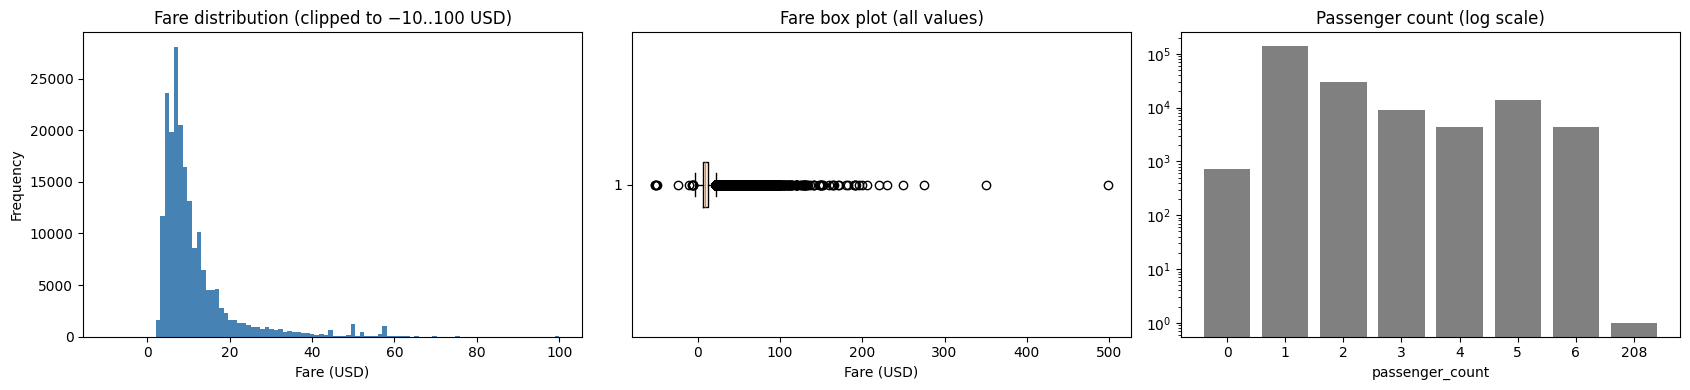

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].hist(df_raw["fare_amount"].clip(-10, 100), bins=100, color="steelblue")
axes[0].set_title("Fare distribution (clipped to −10..100 USD)")
axes[0].set_xlabel("Fare (USD)"); axes[0].set_ylabel("Frequency")
axes[1].boxplot(df_raw["fare_amount"], vert=False)
axes[1].set_title("Fare box plot (all values)"); axes[1].set_xlabel("Fare (USD)")
pc = df_raw["passenger_count"].value_counts().sort_index()
axes[2].bar(pc.index.astype(str), pc.values, color="gray")
axes[2].set_yscale("log"); axes[2].set_title("Passenger count (log scale)"); axes[2].set_xlabel("passenger_count")
plt.tight_layout(); plt.show()

**Findings**
- Only 1 row has missing values (drop-off coordinates).
- Impossible values exist: negative fares (min −52 USD), zero or non-NYC coordinates, 0 and 208 passengers.
- The fare is right-skewed: median 8.5 USD with a few very expensive rides (max 499 USD). High fares are not removed,
  because they can be genuine (airport trips, long rides).

### 3.2 YData Profiling – Automated Data Report

> **Viewing the report:** the interactive report is embedded below as an HTML iframe. GitHub's notebook viewer does not
> render it; open the notebook locally in Jupyter or VS Code (after running this cell) to view it.

In [5]:
import io, warnings, contextlib
warnings.filterwarnings("ignore", category=DeprecationWarning)   # library renaming warning
from ydata_profiling import ProfileReport

# Raw data before cleaning (df_raw is not modified); all 200,000 rows are used
profile = ProfileReport(
    df_raw,
    title="Uber Fares Dataset – Automated Data Report (raw data, before cleaning)",
    correlations={"pearson": {"calculate": True}, "spearman": {"calculate": True},
                  "kendall": {"calculate": False}, "phi_k": {"calculate": False}, "auto": {"calculate": False}},
    interactions={"continuous": False},     # skip the pairwise scatter matrix (memory/time)
    samples={"head": 5, "tail": 5},
    progress_bar=False,
)
with contextlib.redirect_stderr(io.StringIO()):   # hide the progress bar
    profile.to_notebook_iframe()                  # embeds the report below this cell

## 4. Data Cleaning

Fixed rules are used; no statistics are learned from the data, so no leakage occurs.
1. The identifier columns (`Unnamed: 0`, `key`) and the row with missing values are removed.
2. Coordinates must lie inside a New York bounding box: longitude −74.3…−73.7, latitude 40.5…41.0 (JFK, LGA and EWR
   lie inside the box).
3. Fare ≥ 2.5 USD (NYC initial charge). High fares are kept.
4. Passenger count 1–6.
5. Great-circle (Haversine) distance ≥ 0.1 km (removes records with pickup = drop-off).

In [6]:
def haversine_km(lat1, lon1, lat2, lon2):
    # Great-circle (as-the-crow-flies) distance between two points, km
    R = 6371.0
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))

df = df_raw.drop(columns=["Unnamed: 0", "key"]).copy()
n0, log = len(df), []
before = len(df); df = df.dropna(); log.append(("Missing values", before - len(df)))

LON_MIN, LON_MAX, LAT_MIN, LAT_MAX = -74.3, -73.7, 40.5, 41.0
in_box = (df["pickup_longitude"].between(LON_MIN, LON_MAX) & df["dropoff_longitude"].between(LON_MIN, LON_MAX)
          & df["pickup_latitude"].between(LAT_MIN, LAT_MAX) & df["dropoff_latitude"].between(LAT_MIN, LAT_MAX))
before = len(df); df = df[in_box]; log.append(("Coordinates outside NYC box", before - len(df)))
before = len(df); df = df[df["fare_amount"] >= 2.5]; log.append(("Fare < 2.5 USD", before - len(df)))
before = len(df); df = df[df["passenger_count"].between(1, 6)]; log.append(("Passenger count not 1-6", before - len(df)))
df["distance_km"] = haversine_km(df["pickup_latitude"], df["pickup_longitude"],
                                 df["dropoff_latitude"], df["dropoff_longitude"])
before = len(df); df = df[df["distance_km"] >= 0.1]; log.append(("Distance < 0.1 km", before - len(df)))

for name, removed in log:
    print(f"{name:28s}: {removed:6d} rows removed")
print(f"\nBefore cleaning: {n0} rows  ->  after: {len(df)} rows ({len(df) / n0:.1%} retained)")

Missing values              :      1 rows removed
Coordinates outside NYC box :   4419 rows removed
Fare < 2.5 USD              :     21 rows removed
Passenger count not 1-6     :    686 rows removed
Distance < 0.1 km           :   3107 rows removed

Before cleaning: 200000 rows  ->  after: 191766 rows (95.9% retained)


## 5. Train / Validation / Test Split (chronological)

The data are sorted by time and split **without shuffling**: the first 70% for training, the next 15% for validation and
the last 15% for testing.

**Why chronological?** The model learns from past rides and is meant to predict **future** rides. A random split would leak
samples from future periods (e.g. after the 2012 fare increase) into training and give unrealistically optimistic results.
The validation set is used for EarlyStopping and model selection; the test set is used only **once**, at the very end.

In [7]:
df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"], utc=True)
df = df.sort_values("pickup_datetime").reset_index(drop=True)

n = len(df)
TRAIN_END, VAL_END = int(n * 0.70), int(n * 0.85)

def period(a, b):
    p = df["pickup_datetime"].iloc[a:b]
    return f"{p.min():%Y-%m-%d} → {p.max():%Y-%m-%d}"

print(f"Training   : {TRAIN_END:6d} rows | {period(0, TRAIN_END)}")
print(f"Validation : {VAL_END - TRAIN_END:6d} rows | {period(TRAIN_END, VAL_END)}")
print(f"Test       : {n - VAL_END:6d} rows | {period(VAL_END, n)}")

train_part = df.iloc[:TRAIN_END]   # exploratory decisions are made using the TRAINING data ONLY

Training   : 134236 rows | 2009-01-01 → 2013-06-26
Validation :  28765 rows | 2013-06-26 → 2014-06-11
Test       :  28765 rows | 2014-06-11 → 2015-06-30


## 6. Feature Engineering and Scaling

All features are computed row by row and from the inputs only; the target (`fare_amount`) is never used.

**Fare change (training data only):** the New York taxi fare was increased on 4 September 2012. The step in the fare per
km is the reason for using a `fare_regime` (0/1) feature instead of a continuous `year`.

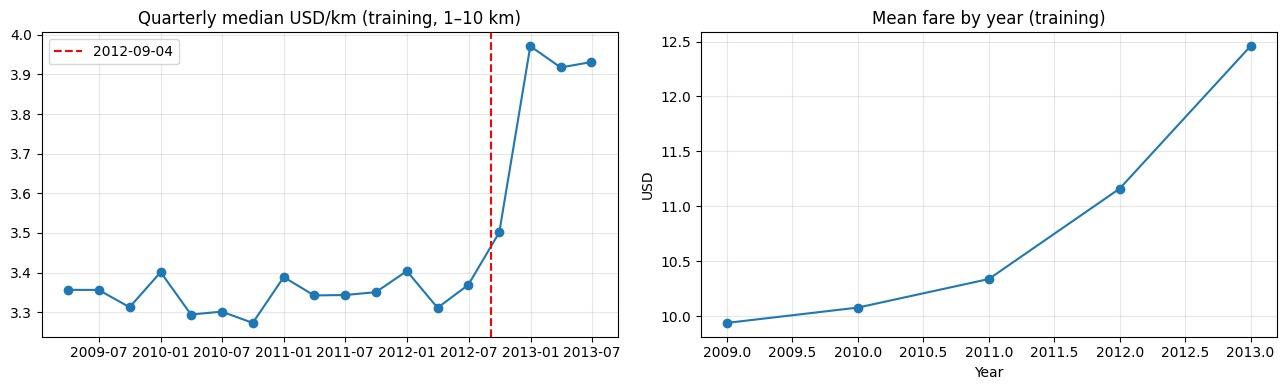

In [8]:
REGIME_DATE = pd.Timestamp("2012-09-04", tz="UTC")
tp = train_part[(train_part["distance_km"] > 1) & (train_part["distance_km"] < 10)].copy()
tp["usd_per_km"] = tp["fare_amount"] / tp["distance_km"]

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
m = tp.set_index("pickup_datetime")["usd_per_km"].resample("QE").median()
ax[0].plot(m.index, m.values, marker="o"); ax[0].axvline(REGIME_DATE, color="red", ls="--", label="2012-09-04")
ax[0].set_title("Quarterly median USD/km (training, 1–10 km)"); ax[0].legend(); ax[0].grid(alpha=.3)
train_part.groupby(train_part["pickup_datetime"].dt.year)["fare_amount"].mean().plot(ax=ax[1], marker="o")
ax[1].set_title("Mean fare by year (training)"); ax[1].set_xlabel("Year"); ax[1].set_ylabel("USD"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

**Time information:** the timestamps are labelled "UTC" in the file, but a daylight-saving-time (DST) analysis indicates
that the recorded hour is already New York local time, so the hour is used **as recorded** (this is an assumption, see
Section 11). Hour and day of week are encoded **cyclically** (so that 23:00 and 00:00 are close). Because the Manhattan
street grid is rotated by about 29° relative to true north, `manhattan_rot_km` is computed with this angle.

In [9]:
REF_DATE = pd.Timestamp("2009-01-01", tz="UTC")   # fixed reference date (not learned from the data)
KM_PER_DEG_LAT = 111.0
GRID_ANGLE = np.radians(29.0)                      # angle of the Manhattan grid relative to north

def add_features(d):
    d = d.copy()
    ts = d["pickup_datetime"]                      # recorded hour = New York local time
    hour, dow = ts.dt.hour, ts.dt.dayofweek
    # Time (cyclical encoding)
    d["month"] = ts.dt.month
    d["is_weekend"] = (dow >= 5).astype(int)
    d["hour_sin"], d["hour_cos"] = np.sin(2 * np.pi * hour / 24), np.cos(2 * np.pi * hour / 24)
    d["dow_sin"], d["dow_cos"] = np.sin(2 * np.pi * dow / 7), np.cos(2 * np.pi * dow / 7)
    # Fare regime and time trend
    d["fare_regime"] = (ts >= REGIME_DATE).astype(int)
    d["elapsed_years"] = (ts - REF_DATE).dt.days / 365.25
    # Geographic: coordinate differences, km components, Manhattan distances, direction
    d["dlat"] = d["dropoff_latitude"] - d["pickup_latitude"]
    d["dlon"] = d["dropoff_longitude"] - d["pickup_longitude"]
    mean_lat = np.radians((d["pickup_latitude"] + d["dropoff_latitude"]) / 2)
    d["ns_km"] = d["dlat"] * KM_PER_DEG_LAT
    d["ew_km"] = d["dlon"] * KM_PER_DEG_LAT * np.cos(mean_lat)
    d["manhattan_km"] = d["ns_km"].abs() + d["ew_km"].abs()
    x_rot = d["ew_km"] * np.cos(GRID_ANGLE) - d["ns_km"] * np.sin(GRID_ANGLE)
    y_rot = d["ew_km"] * np.sin(GRID_ANGLE) + d["ns_km"] * np.cos(GRID_ANGLE)
    d["manhattan_rot_km"] = x_rot.abs() + y_rot.abs()
    bearing = np.arctan2(d["ns_km"], d["ew_km"])
    d["bearing_sin"], d["bearing_cos"] = np.sin(bearing), np.cos(bearing)
    return d

df = add_features(df)

FEATURE_GROUPS = {
    "Basic": ["pickup_longitude", "pickup_latitude", "dropoff_longitude", "dropoff_latitude",
              "passenger_count", "distance_km"],
    "Time": ["month", "is_weekend", "hour_sin", "hour_cos", "dow_sin", "dow_cos"],
    "Fare regime / trend": ["fare_regime", "elapsed_years"],
    "Geographic": ["dlat", "dlon", "ns_km", "ew_km", "manhattan_km", "manhattan_rot_km", "bearing_sin", "bearing_cos"],
}
FEATURES = [f for group in FEATURE_GROUPS.values() for f in group]
TARGET = "fare_amount"

# The feature order must match the order the saved final model was trained with (the weights depend on it)
RESULTS = pd.read_csv(RESULTS_DIR / "FINAL_RESULTS.csv", float_precision="round_trip")
final_row = RESULTS[RESULTS["final_selected"]].iloc[0]
assert FEATURES == final_row["feature_list"].split("|")

print(f"Number of input features: {len(FEATURES)}")
display(pd.DataFrame([(g, len(c), ", ".join(c)) for g, c in FEATURE_GROUPS.items()],
                     columns=["Group", "Count", "Features"]).set_index("Group"))

Number of input features: 22


,Count,Features
Group,,
Basic,6,"pickup_longitude, pickup_latitude, dropoff_lon..."
Time,6,"month, is_weekend, hour_sin, hour_cos, dow_sin..."
Fare regime / trend,2,"fare_regime, elapsed_years"
Geographic,8,"dlat, dlon, ns_km, ew_km, manhattan_km, manhat..."


**Scaling:** `StandardScaler` (mean 0, std 1) is fitted **on the training set only**; the validation and test sets are
transformed with the same parameters. This prevents statistics of future periods from leaking into the model.

In [10]:
scaler = StandardScaler().fit(df.iloc[:TRAIN_END][FEATURES])     # TRAINING data ONLY

def prepare(a, b):
    X = scaler.transform(df.iloc[a:b][FEATURES]).astype("float32")
    y = df.iloc[a:b][TARGET].values.astype("float32")
    return X, y

X_train, y_train = prepare(0, TRAIN_END)
X_val, y_val = prepare(TRAIN_END, VAL_END)
X_test, y_test = prepare(VAL_END, n)

assert scaler.n_samples_seen_ == TRAIN_END
print(f"Rows seen by the scaler: {scaler.n_samples_seen_} (= training set)")
print("X_train:", X_train.shape, "| X_val:", X_val.shape, "| X_test:", X_test.shape)

# Mean ≈ 0 and std ≈ 1 on training; in later periods (validation/test) the time features shift
show = ["distance_km", "hour_sin", "fare_regime", "elapsed_years"]
idx = [FEATURES.index(f) for f in show]
display(pd.DataFrame({"train mean": X_train[:, idx].mean(0), "train std": X_train[:, idx].std(0),
                      "validation mean": X_val[:, idx].mean(0), "test mean": X_test[:, idx].mean(0)}, index=show))

Rows seen by the scaler: 134236 (= training set)
X_train: (134236, 22) | X_val: (28765, 22) | X_test: (28765, 22)


,train mean,train std,validation mean,test mean
distance_km,-0.0000,1.0000,0.0317,0.0457
hour_sin,0.0000,1.0000,0.0118,0.0113
fare_regime,-0.0000,1.0000,2.0933,2.0933
elapsed_years,-0.0000,1.0000,2.0856,2.8543


## 7. Baseline Model: Linear Regression

A single linear neuron using the same 22 features: $\hat y = w^\top x + b$ (the same model as ADALINE; `sklearn` finds the
least-squares solution in closed form). The contribution of the MLP's hidden layers is measured against this model.

In [11]:
def regression_metrics(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "R2": r2_score(y_true, y_pred)}

lin_reg = LinearRegression().fit(X_train, y_train)
display(pd.DataFrame({"Linear Regression – validation": regression_metrics(y_val, lin_reg.predict(X_val))}).T)

,MAE,RMSE,R2
Linear Regression – validation,2.4425,4.6929,0.8047


## 8. MLP Architecture and Model Selection

Five different network structures were compared to determine the most suitable MLP architecture.

### 8.1 Architecture comparison [Saved experiment results]

The 100 training runs (5 architectures × 5 seeds × 4 chronological windows) were performed **beforehand**; no retraining
happens here, only the saved results are read. Everything except the architecture is fixed; the test set was not used.

| Architecture | Mean validation RMSE (USD) |
|---|---:|
| 16 | 3.663 |
| 32 | 3.656 |
| 32 → 16 | 3.643 |
| **64 → 32** | **3.594** |
| 64 → 32 → 16 | 3.596 |

*Each value is the mean of 20 runs (5 seeds × 4 windows); the next cell verifies these values against the saved CSV files.*

> **Reproducibility:** the complete original code that produced these 100 training runs (data windows, checkpointed
> training, parallel execution and the selection rule) is in **Appendix A**. It is not executed by default
> (`RUN_ARCHITECTURE_EXPERIMENTS = False`).
>
> **Identifiers in the saved results:** the result files keep the identifiers of the original (Turkish) experiment code so
> that the saved results remain reproducible: windows `kayan_0`, `kayan_1`, `kayan_2` (expanding windows 0–2) and `ana`
> (main split); stage `v3-Mimari` (architecture experiment); in `FINAL_MODEL_SELECTION.csv`: `mimari` = architecture,
> `parametre` = parameters, `kararli` = stable, `pratik_esdeger` = practically equivalent, `secilen` = selected,
> `esl_fark` = paired difference, `GA95_alt/ust` = 95% CI lower/upper.

In [12]:
# [Saved experiment results] The 100 architecture runs were performed earlier; they are only read here (no retraining)
arch_runs = RESULTS[RESULTS["stage"] == "v3-Mimari"]
assert len(arch_runs) == 100 and (arch_runs["status"] == "OK").all()

ORDER = ["16", "32", "32-16", "64-32", "64-32-16"]
WINDOWS = ["kayan_0", "kayan_1", "kayan_2", "ana"]          # window identifiers as stored in FINAL_RESULTS.csv
sel = pd.read_csv(RESULTS_DIR / "FINAL_MODEL_SELECTION.csv", dtype={"mimari": str}).set_index("mimari").loc[ORDER]
EPS = float(sel["epsilon_USD"].iloc[0])

# Do the values in the table above match the saved results?
mean_rmse = arch_runs.groupby("architecture")["val_RMSE"].mean().loc[ORDER]
assert np.allclose(mean_rmse, sel["val_RMSE_genel_ort"])
assert list(mean_rmse.round(3)) == [3.663, 3.656, 3.643, 3.594, 3.596]
SELECTED = sel.index[sel["secilen"]][0]
assert SELECTED == "64-32"

print(f"Table values match the saved CSV ✓ | ε = {EPS:.3f} USD | all architectures stable: {bool(sel['kararli'].all())} | "
      f"practically equivalent: {list(sel.index[sel['pratik_esdeger']])} | selected: {SELECTED}")

Table values match the saved CSV ✓ | ε = 0.025 USD | all architectures stable: True | practically equivalent: ['64-32'] | selected: 64-32


**Why 64 → 32?** The selection followed a rule defined before the results were seen (not simply the lowest mean):
1. **Stability:** no NaN and an early-stop rate (best epoch ≤ 3) of ≤ 20% → all five architectures are stable.
2. **Reference:** the stable architecture with the lowest mean validation RMSE → 64-32.
3. **Practical equivalence:** mean paired difference to the reference (same seed, same window) ≤ ε **and** no window with a
   difference > 2ε (ε = typical seed-to-seed variation).
4. **Selection:** the architecture with the fewest parameters among the equivalent and stable ones.

The smaller networks (16, 32, 32-16) are not equivalent (their differences are 2–3 times ε). 64-32-16 is almost identical
on average, but its difference exceeds 2ε in one window and it has more parameters → **64-32 is selected**.
Paired differences, 95% confidence intervals and the window analysis: **Section 8.2**.

### 8.2 Architecture Comparison Details [Saved experiment results]

5 architectures (16, 32, 32-16, 64-32, 64-32-16) × 5 seeds (42, 123, 456, 789, 2026) × 4 expanding chronological windows =
100 training runs. Windows (training → validation on the immediately following period): `kayan_0` first 25% → 25–40% ·
`kayan_1` first 40% → 40–55% · `kayan_2` first 55% → 55–70% · `ana` first 70% → 70–85% (the split of Section 5).
Selection rule: Section 8.1.

ε = 0.0250 USD (2ε = 0.050)


split,parameters,kayan_0,kayan_1,kayan_2,ana,overall mean,paired diff. vs 64-32,95% CI,worst window diff.,stable,practically equivalent,selected
architecture,,,,,,,,,,,,
16,385,3.6970,2.8207,4.0827,4.0533,3.6634,0.0692,[+0.015; +0.123],0.1653,True,False,False
32,769,3.6954,2.8057,4.1118,4.0101,3.6557,0.0616,[+0.014; +0.110],0.1645,True,False,False
32-16,1281,3.7034,2.8007,4.1000,3.9692,3.6433,0.0491,[+0.009; +0.089],0.1528,True,False,False
64-32,3585,3.7335,2.8080,3.9473,3.8879,3.5942,0.0000,reference,0.0000,True,True,True
64-32-16,4097,3.7190,2.8013,4.0120,3.8499,3.5955,0.0014,[-0.029; +0.032],0.0647,True,False,False


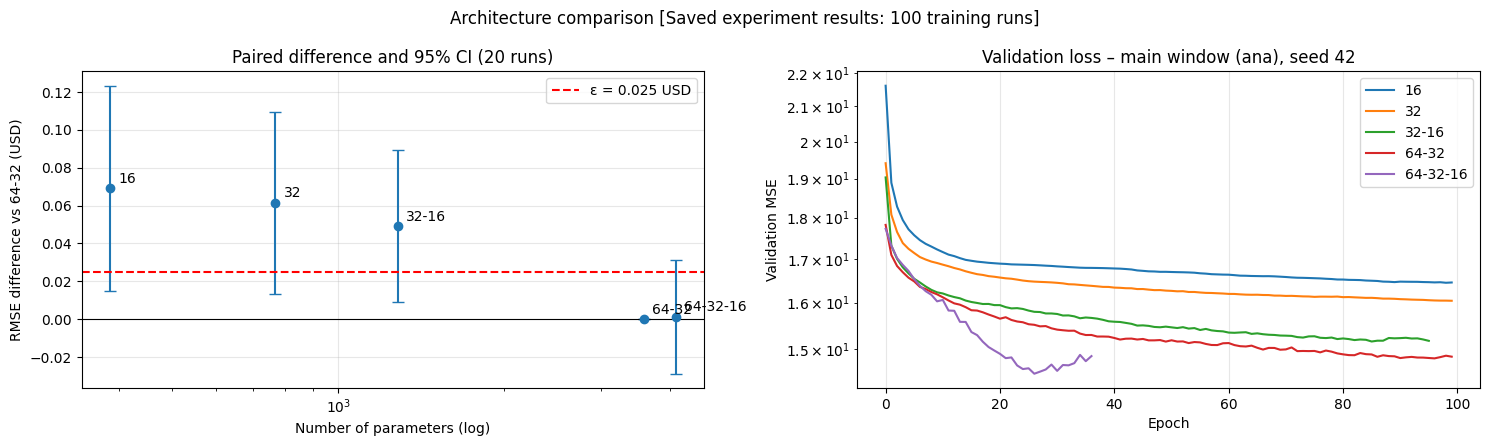

In [13]:
# Mean validation RMSE (USD) per window and all criteria of the selection rule
arch_table = arch_runs.pivot_table(index="architecture", columns="split", values="val_RMSE", aggfunc="mean").loc[ORDER, WINDOWS]
arch_table.insert(0, "parameters", arch_runs.groupby("architecture")["n_params"].first().loc[ORDER])
arch_table["overall mean"] = arch_runs.groupby("architecture")["val_RMSE"].mean().loc[ORDER]
arch_table["paired diff. vs 64-32"] = sel["esl_fark_ort_vs_64-32"]
arch_table["95% CI"] = ["reference" if a == "64-32" else f"[{lo:+.3f}; {hi:+.3f}]"
                       for a, lo, hi in zip(ORDER, sel["GA95_alt"], sel["GA95_ust"])]
arch_table["worst window diff."] = sel["en_kotu_pencere_farki"]
arch_table["stable"] = sel["kararli"]
arch_table["practically equivalent"] = sel["pratik_esdeger"]
arch_table["selected"] = sel["secilen"]
print(f"ε = {EPS:.4f} USD (2ε = {2 * EPS:.3f})")
display(arch_table.rename_axis("architecture"))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
mid = sel["esl_fark_ort_vs_64-32"]
ax[0].errorbar(sel["parametre"], mid, yerr=[mid - sel["GA95_alt"], sel["GA95_ust"] - mid], fmt="o", capsize=4)
for a, r in sel.iterrows():
    ax[0].annotate(a, (r["parametre"], r["esl_fark_ort_vs_64-32"]), xytext=(6, 4), textcoords="offset points")
ax[0].axhline(EPS, color="r", ls="--", label=f"ε = {EPS:.3f} USD"); ax[0].axhline(0, color="k", lw=.8)
ax[0].set_xscale("log"); ax[0].set_xlabel("Number of parameters (log)"); ax[0].set_ylabel("RMSE difference vs 64-32 (USD)")
ax[0].set_title("Paired difference and 95% CI (20 runs)"); ax[0].legend(); ax[0].grid(alpha=.3)
for a in ORDER:
    r = arch_runs[(arch_runs["architecture"] == a) & (arch_runs["split"] == "ana") & (arch_runs["seed"] == SEED)].iloc[0]
    ax[1].plot([float(v) for v in r["history_val_loss"].split("|")], label=a)
ax[1].set_yscale("log"); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Validation MSE")
ax[1].set_title("Validation loss – main window (ana), seed 42"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.suptitle("Architecture comparison [Saved experiment results: 100 training runs]"); plt.tight_layout(); plt.show()

No architecture is best in every window (e.g. in `kayan_0`, trained on little data, the small networks are slightly
better); the worst window difference of 64-32-16 occurs in the `kayan_2` window.

### 8.3 Selected MLP: 22 → 64 → 32 → 1

- **Input layer:** the 22 scaled features.
- **Hidden layers:** 64 and 32 neurons with **ReLU**; they learn non-linear relationships (e.g. distance × location × direction).
- **Output layer:** 1 neuron with **linear** activation → predicted fare (USD).

In [14]:
def build_mlp(n_inputs):
    return keras.Sequential([
        keras.Input(shape=(n_inputs,)),
        layers.Dense(64, activation="relu", kernel_initializer="glorot_uniform"),   # hidden layer 1
        layers.Dense(32, activation="relu", kernel_initializer="glorot_uniform"),   # hidden layer 2
        layers.Dense(1, activation="linear"),                                       # output: fare (USD)
    ], name="uber_mlp_22_64_32_1")

model = build_mlp(len(FEATURES))
model.summary()
assert model.count_params() == (22 * 64 + 64) + (64 * 32 + 32) + (32 * 1 + 1) == 3585

Model: "uber_mlp_22_64_32_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,585 (14.00 KB)

 Trainable params: 3,585 (14.00 KB)

 Non-trainable params: 0 (0.00 B)

## 9. Model Training

| Setting | Value |
|---|---|
| Loss | MSE |
| Optimizer | Adam, learning rate 0.001 |
| Batch size | 64 |
| Epochs | at most 100 |
| EarlyStopping | monitors `val_loss`, patience 10, best weights restored |
| Seed | 42 |

**In every mini-batch:** forward pass → MSE loss → backpropagation (gradients, BP1–BP4) → weight update with Adam

> **Training or loading?** `train_mlp()` is the actual training code. Because `TRAIN_FROM_SCRATCH = False` in this notebook,
> the model is **not retrained**: the loss history and the best weights of the model previously trained with the same code
> are loaded from the checkpoint **[Saved result]**. With `True`, the model is trained from scratch with the same settings.

In [15]:
# ---- Training configuration of the final model ----
LOSS = "mse"
LEARNING_RATE = 1e-3
BATCH_SIZE = 64
MAX_EPOCHS = 100
PATIENCE = 10

def train_mlp():
    keras.utils.set_random_seed(SEED)
    mlp = build_mlp(len(FEATURES))
    # steps_per_execution: 64 mini-batches are processed in one TF call; a speed setting only, the math is unchanged
    mlp.compile(optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE), loss=LOSS, steps_per_execution=64)
    early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
    hist = mlp.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=MAX_EPOCHS, batch_size=BATCH_SIZE,
                   callbacks=[keras.callbacks.TerminateOnNaN(), early_stop], verbose=0)
    return mlp, hist.history

# The settings in the code must match the configuration of the saved final model
saved_cfg = json.loads(final_row["config_json"])
assert (saved_cfg["arch"], saved_cfg["activation"], saved_cfg["init"], saved_cfg["loss"], saved_cfg["optimizer"],
        saved_cfg["lr"], saved_cfg["batch"], saved_cfg["max_epochs"], saved_cfg["early_stopping"], saved_cfg["seed"]) == \
       ([64, 32], "relu", "glorot_uniform", LOSS, "adam", LEARNING_RATE, BATCH_SIZE, MAX_EPOCHS, True, SEED)

TRAIN_FROM_SCRATCH = False      # True: the model is retrained with the same code (a few minutes on a CPU)
run_dir = CKPT_DIR / f"v3-Son_{hashlib.md5(final_row['config_json'].encode()).hexdigest()[:10]}"

if TRAIN_FROM_SCRATCH or not run_dir.exists():
    model, history = train_mlp()
    SOURCE = "trained in this run"
else:
    # [Saved result] Final checkpoint: loss history + best weights kept by EarlyStopping
    # (file tag "son" = "end of epoch" in the original code's checkpoint naming)
    last = sorted(run_dir.glob("ckpt_*_son.json"))[-1]
    history = json.loads(last.read_text(encoding="utf-8"))["history"]
    best = np.load(str(last).replace(".json", "_best.npz"))
    model = build_mlp(len(FEATURES))
    model.set_weights([best[f"arr_{i}"] for i in range(len(best.files))])
    SOURCE = "[Saved result] weights loaded from checkpoint"

best_epoch = int(np.argmin(history["val_loss"])) + 1
print(f"Model source : {SOURCE}")
print(f"Epochs run   : {len(history['loss'])} | best epoch: {best_epoch} | "
      f"best validation MSE: {min(history['val_loss']):.4f}")

Model source : [Saved result] weights loaded from checkpoint
Epochs run   : 100 | best epoch: 97 | best validation MSE: 14.8118


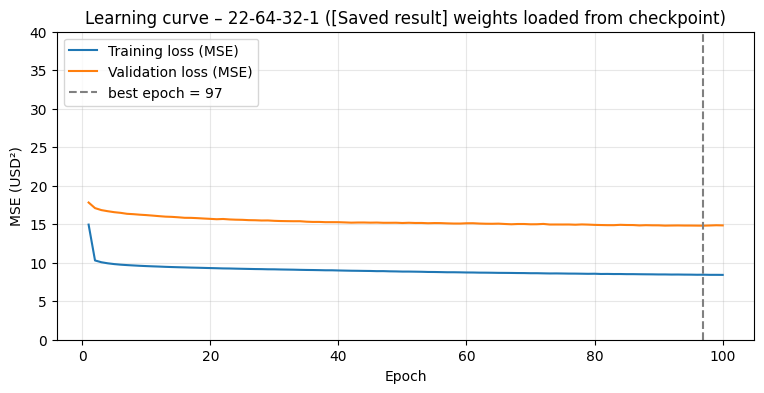

In [16]:
plt.figure(figsize=(9, 4))
ep = np.arange(1, len(history["loss"]) + 1)
plt.plot(ep, history["loss"], label="Training loss (MSE)")
plt.plot(ep, history["val_loss"], label="Validation loss (MSE)")
plt.axvline(best_epoch, color="gray", ls="--", label=f"best epoch = {best_epoch}")
plt.ylim(0, 40); plt.xlabel("Epoch"); plt.ylabel("MSE (USD²)")
plt.title(f"Learning curve – 22-64-32-1 ({SOURCE})"); plt.legend(); plt.grid(alpha=.3); plt.show()

### 9.1 Backpropagation Verification (BP1–BP4)

Using the final model's actual weights and a training mini-batch of 256 samples, the gradients are computed **manually**
in NumPy and compared with TensorFlow's automatic differentiation (`GradientTape`). The notation follows the four
fundamental backpropagation equations BP1–BP4 (Nielsen, 2015, Ch. 2), written here in mini-batch (row-vector) form.

| | Equation | Code |
|---|---|---|
| **BP1** | $\delta^{L} = \frac{2}{B}(\hat y - y)$ (linear output) | `d = 2 * (yhat - y) / B` |
| **BP2** | $\delta^{l} = (\delta^{l+1}\, W^{l+1\,\top}) \odot \mathbb{1}[Z^{l} > 0]$ | `d = (d @ W.T) * (Z > 0)` |
| **BP3** | $\partial L/\partial W^{l} = A^{l-1\,\top}\,\delta^{l}$ | `A.T @ d` |
| **BP4** | $\partial L/\partial b^{l} = \sum_i \delta^{l}_i$ | `d.sum(axis=0)` |

The implementation is in **9.1.a**, the comparison results in **9.1.b**.

#### 9.1.a Implementation: manual forward/backward pass in NumPy and comparison with TensorFlow

In [17]:
# --- Manual forward + backward pass in NumPy, using the final model's actual weights ---
Ws = model.get_weights()                                   # [W1, b1, W2, b2, W3, b3]
rng_bp = np.random.default_rng(0)
idx_bp = rng_bp.choice(len(X_train), 256, replace=False)
Xb, yb = X_train[idx_bp].astype("float64"), y_train[idx_bp].astype("float64").reshape(-1, 1)
B = len(Xb)

# Forward pass
A, Zs, As = Xb, [], [Xb]
n_layers = len(Ws) // 2
for l in range(n_layers):
    W, b = Ws[2 * l].astype("float64"), Ws[2 * l + 1].astype("float64")
    Z = A @ W + b
    A = Z if l == n_layers - 1 else np.maximum(0.0, Z)     # last layer linear, others ReLU
    Zs.append(Z); As.append(A)
loss_np = float(np.mean((A - yb) ** 2))

# Backpropagation: BP1 → BP3/BP4 → BP2
grads_np = [None] * len(Ws)
d = 2.0 * (A - yb) / B                                     # BP1
for l in reversed(range(n_layers)):
    grads_np[2 * l] = As[l].T @ d                          # BP3
    grads_np[2 * l + 1] = d.sum(axis=0)                    # BP4
    if l > 0:
        d = (d @ Ws[2 * l].astype("float64").T) * (Zs[l - 1] > 0)   # BP2

In [18]:
# --- The same gradients with TensorFlow automatic differentiation; comparison table ---
with tf.GradientTape() as tape:
    yhat_tf = model(tf.constant(Xb, dtype=tf.float32), training=False)
    loss_tf = keras.losses.MeanSquaredError()(tf.constant(yb, dtype=tf.float32), yhat_tf)
grads_tf = [g.numpy() for g in tape.gradient(loss_tf, model.trainable_variables)]

BP_USED = ["BP1 + BP2 + BP3", "BP1 + BP2 + BP4", "BP1 + BP2 + BP3", "BP1 + BP2 + BP4", "BP1 + BP3", "BP1 + BP4"]
bp_rows = []
for i, (gn, gt) in enumerate(zip(grads_np, grads_tf)):
    rel = np.linalg.norm(gn - gt) / max(np.linalg.norm(gn) + np.linalg.norm(gt), 1e-12)
    bp_rows.append({"parameter": f"{'W' if i % 2 == 0 else 'b'}{i // 2 + 1}", "equations used": BP_USED[i],
                    "‖grad‖ NumPy": np.linalg.norm(gn), "‖grad‖ TF": np.linalg.norm(gt), "relative difference": f"{rel:.2e}"})
bp_summary = pd.DataFrame(bp_rows).set_index("parameter")
assert max(float(r["relative difference"]) for r in bp_rows) < 1e-4

# One Adam step with the same gradient (demonstration only; applied to a copy, the actual model is unchanged)
_m = keras.models.clone_model(model); _m.set_weights(Ws)
keras.optimizers.Adam(learning_rate=LEARNING_RATE).apply_gradients(
    zip([tf.constant(g, dtype=tf.float32) for g in grads_np], _m.trainable_variables))
loss_after = float(keras.losses.MeanSquaredError()(tf.constant(yb, dtype=tf.float32), _m(tf.constant(Xb, dtype=tf.float32))))

#### 9.1.b Verification summary

In [19]:
print(f"Mini-batch loss: NumPy {loss_np:.6f} | Keras {float(loss_tf):.6f}")
display(bp_summary)
print(f"One Adam step (η = 0.001, with the manually computed gradient): loss {loss_np:.4f} → {loss_after:.4f}")

Mini-batch loss: NumPy 7.016436 | Keras 7.016437


,equations used,‖grad‖ NumPy,‖grad‖ TF,relative difference
parameter,,,,
W1,BP1 + BP2 + BP3,8.0034,8.0034,3.26e-07
b1,BP1 + BP2 + BP4,1.2224,1.2224,3.05e-07
W2,BP1 + BP2 + BP3,6.6695,6.6695,2.80e-07
b2,BP1 + BP2 + BP4,0.3114,0.3114,2.94e-07
W3,BP1 + BP3,27.6888,27.6888,2.48e-07
b3,BP1 + BP4,0.3017,0.3017,3.16e-07


One Adam step (η = 0.001, with the manually computed gradient): loss 7.0164 → 6.6294


**Result:** in every layer the relative difference is at float32 rounding level (< 10⁻⁴, checked with `assert`) → the
manually written BP1–BP4 give the same gradients as TensorFlow, and one Adam step with this gradient reduces the loss.

## 10. Model Performance: Linear Regression vs MLP

Both models use the same 22 features and the same scaling. The **validation** set was used for model selection; the
**test** set (2014-06 → 2015-06) is reported here once. Because the test period was examined during an earlier
development version, it is not a completely untouched independent test ("historically seen").

In [20]:
preds = {
    "Linear Regression": (lin_reg.predict(X_val), lin_reg.predict(X_test)),
    "MLP 22-64-32-1": (model.predict(X_val, batch_size=8192, verbose=0).ravel(),
                       model.predict(X_test, batch_size=8192, verbose=0).ravel()),
}
results = pd.concat({
    "Validation": pd.DataFrame({k: regression_metrics(y_val, p[0]) for k, p in preds.items()}).T,
    "Test": pd.DataFrame({k: regression_metrics(y_test, p[1]) for k, p in preds.items()}).T}, axis=1)
display(results)

# Consistency check: identical to the v3 rows of the saved final comparison table (FINAL_COMPARISON.csv)?
saved_cmp = pd.read_csv(RESULTS_DIR / "FINAL_COMPARISON.csv", header=[0, 1], index_col=0, float_precision="round_trip")
saved_v3 = saved_cmp[saved_cmp.index.str.startswith("v3 –")]
max_diff = np.abs(results.values - saved_v3.values).max()
assert max_diff < 1e-6
print(f"Largest difference from the saved results: {max_diff:.1e}")

lr_t, mlp_t = results.loc["Linear Regression", "Test"], results.loc["MLP 22-64-32-1", "Test"]
print(f"Test RMSE: {lr_t['RMSE']:.3f} → {mlp_t['RMSE']:.3f} USD ({1 - mlp_t['RMSE'] / lr_t['RMSE']:.1%} reduction) | "
      f"Test MAE: {lr_t['MAE']:.3f} → {mlp_t['MAE']:.3f} USD | MLP test mean residual (y−ŷ): "
      f"{np.mean(y_test - preds['MLP 22-64-32-1'][1]):+.3f} USD")

Validation                 Test              
                         MAE   RMSE     R2    MAE   RMSE     R2
Linear Regression     2.4425 4.6929 0.8047 2.4246 4.1809 0.8535
MLP 22-64-32-1        1.8868 3.8486 0.8686 1.9196 3.3213 0.9075

Largest difference from the saved results: 0.0e+00
Test RMSE: 4.181 → 3.321 USD (20.6% reduction) | Test MAE: 2.425 → 1.920 USD | MLP test mean residual (y−ŷ): +0.189 USD


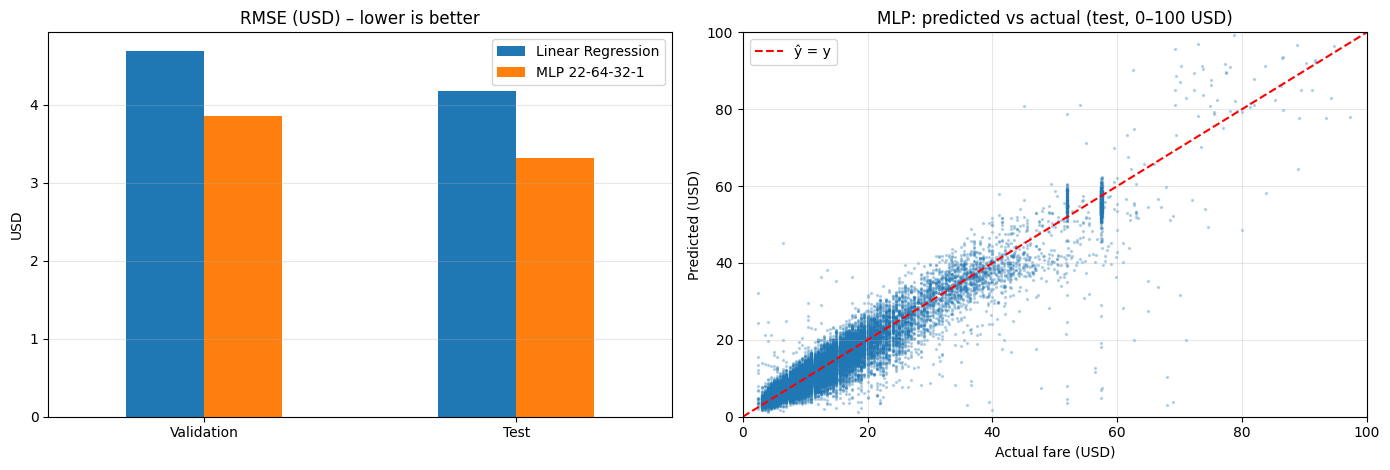

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
# (1) RMSE comparison
results.xs("RMSE", axis=1, level=1).T.plot.bar(ax=axes[0], rot=0)
axes[0].set_title("RMSE (USD) – lower is better"); axes[0].set_ylabel("USD"); axes[0].grid(alpha=.3, axis="y")
# (2) Predicted vs actual (test, MLP)
p_mlp = preds["MLP 22-64-32-1"][1]
axes[1].scatter(y_test, p_mlp, s=2, alpha=0.25)
axes[1].plot([0, 100], [0, 100], "r--", label="ŷ = y")
axes[1].set_xlim(0, 100); axes[1].set_ylim(0, 100)
axes[1].set_xlabel("Actual fare (USD)"); axes[1].set_ylabel("Predicted (USD)")
axes[1].set_title("MLP: predicted vs actual (test, 0–100 USD)"); axes[1].legend(); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

**Interpretation:** the MLP outperforms Linear Regression on all three metrics in both validation and test. On the test
set, RMSE drops from 4.181 to 3.321 USD (**20.6% reduction**), MAE from 2.425 to 1.920 USD, and R² rises from 0.853 to
0.908. Because both models use the same inputs, this difference comes from the non-linear relationships learned by the
hidden layers.

### 10.1 Error Analysis: where does the model still make errors? (validation set)

Residual $e = y - \hat y$: **positive = under-prediction**. Airport ride: pickup or drop-off within 2 km of JFK, LGA or
EWR. All groups and charts: Section 10.2.

In [22]:
val_df = df.iloc[TRAIN_END:VAL_END].copy()
for name, (p, _) in preds.items():
    val_df[name] = p

val_df["fare range"] = pd.cut(val_df[TARGET], [0, 5, 10, 20, 40, 60, np.inf],
                              labels=["<5", "5–10", "10–20", "20–40", "40–60", "≥60"], right=False)
AIRPORTS = {"JFK": (40.6413, -73.7781), "LGA": (40.7769, -73.8740), "EWR": (40.6895, -74.1745)}
near = {k: (haversine_km(val_df["pickup_latitude"], val_df["pickup_longitude"], lat, lon) < 2)
           | (haversine_km(val_df["dropoff_latitude"], val_df["dropoff_longitude"], lat, lon) < 2)
        for k, (lat, lon) in AIRPORTS.items()}
val_df["airport"] = np.select(list(near.values()), list(near.keys()), "non-airport")

def group_errors(col):
    rows = []
    for g, sub in val_df.groupby(col, observed=True):
        for name in preds:
            e = sub[TARGET] - sub[name]
            rows.append({col: g, "model": name, "n": len(sub), "MAE": e.abs().mean(), "mean residual": e.mean()})
    return pd.DataFrame(rows).pivot_table(index=col, columns="model", values=["n", "MAE", "mean residual"], observed=True)

err_fare = group_errors("fare range").reindex(["<5", "5–10", "10–20", "20–40", "40–60", "≥60"])
err_air = group_errors("airport").loc[["non-airport", "LGA", "JFK", "EWR"]]

# Summary table: only the hardest groups
LR_N, MLP_N = "Linear Regression", "MLP 22-64-32-1"
def summary_row(n, mae_lr, mae_mlp, res_mlp):
    return {"n": int(n), "MAE – Linear R.": mae_lr, "MAE – MLP": mae_mlp, "MLP mean residual": res_mlp}
e_lr, e_mlp = val_df[TARGET] - val_df[LR_N], val_df[TARGET] - val_df[MLP_N]
hard = {"All validation": summary_row(len(val_df), e_lr.abs().mean(), e_mlp.abs().mean(), e_mlp.mean())}
for tbl, groups, label in [(err_fare, ["40–60", "≥60"], "Fare {} USD"), (err_air, ["LGA", "JFK", "EWR"], "Airport {}")]:
    for g in groups:
        hard[label.format(g)] = summary_row(tbl.loc[g, ("n", MLP_N)], tbl.loc[g, ("MAE", LR_N)],
                                            tbl.loc[g, ("MAE", MLP_N)], tbl.loc[g, ("mean residual", MLP_N)])
display(pd.DataFrame(hard).T.astype({"n": int}).round(3))

,n,MAE – Linear R.,MAE – MLP,MLP mean residual
All validation,28765,2.4430,1.8870,0.1930
Fare 40–60 USD,897,10.2740,6.0010,4.5410
Fare ≥60 USD,108,35.0110,20.5310,12.1930
Airport LGA,1011,7.2200,3.9770,1.4740
Airport JFK,637,7.6220,4.6850,-0.4300
Airport EWR,52,28.8300,9.9800,-4.0050


### 10.2 Detailed Error Analysis: all groups and residual distribution

MAE                    mean residual                                n               
model      Linear Regression MLP 22-64-32-1 Linear Regression MLP 22-64-32-1 Linear Regression MLP 22-64-32-1
fare range                                                                                                   
<5                    2.5460         1.2600           -2.5450        -1.1690        2,183.0000     2,183.0000
5–10                  1.5220         1.0680           -1.3340        -0.3500       12,817.0000    12,817.0000
10–20                 1.8240         1.9660            0.5000         0.3580        9,851.0000     9,851.0000
20–40                 4.8930         3.7340            3.5810         1.2600        2,909.0000     2,909.0000
40–60                10.2740         6.0010            9.4440         4.5410          897.0000       897.0000
≥60                  35.0110        20.5310           34.7550        12.1930          108.0000       108.0000

MAE                    mean residual                                n               
model       Linear Regression MLP 22-64-32-1 Linear Regression MLP 22-64-32-1 Linear Regression MLP 22-64-32-1
airport                                                                                                       
non-airport            2.0910         1.7270           -0.1920         0.1680       27,065.0000    27,065.0000
LGA                    7.2200         3.9770            5.7300         1.4740        1,011.0000     1,011.0000
JFK                    7.6220         4.6850            4.4090        -0.4300          637.0000       637.0000
EWR                   28.8300         9.9800           28.8300        -4.0050           52.0000        52.0000

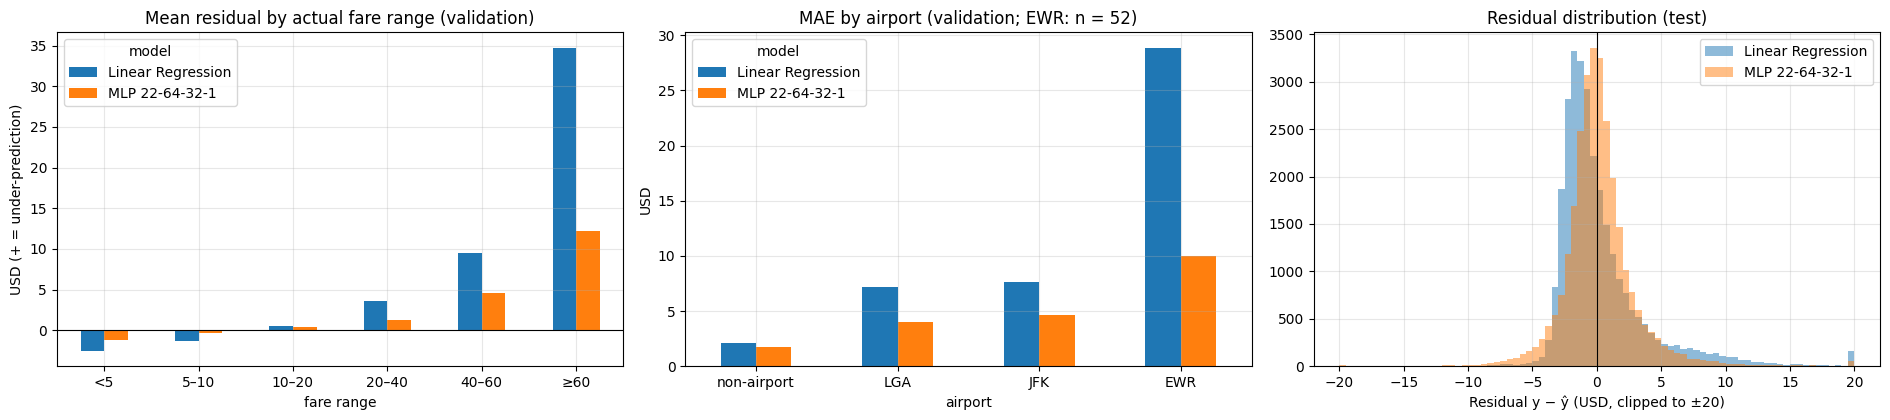

In [23]:
display(err_fare.round(3)); display(err_air.round(3))

fig, ax = plt.subplots(1, 3, figsize=(19, 4.3))
err_fare["mean residual"].plot.bar(ax=ax[0], rot=0); ax[0].axhline(0, color="k", lw=.8)
ax[0].set_title("Mean residual by actual fare range (validation)"); ax[0].set_ylabel("USD (+ = under-prediction)"); ax[0].grid(alpha=.3)
err_air["MAE"].plot.bar(ax=ax[1], rot=0)
ax[1].set_title("MAE by airport (validation; EWR: n = 52)"); ax[1].set_ylabel("USD"); ax[1].grid(alpha=.3)
for name, (_, p) in preds.items():
    ax[2].hist(np.clip(y_test - p, -20, 20), bins=80, alpha=0.5, label=name)
ax[2].axvline(0, color="k", lw=.8)
ax[2].set_xlabel("Residual y − ŷ (USD, clipped to ±20)"); ax[2].set_title("Residual distribution (test)")
ax[2].legend(); ax[2].grid(alpha=.3)
plt.tight_layout(); plt.show()

**Findings**
- **Expensive rides:** the MLP clearly reduces the error compared with Linear Regression, but still systematically
  **under-predicts** rides above 40 USD (positive mean residual).
- **Airport rides:** the MAE is about 2–5 times the overall average. EWR has only 52 samples and should be interpreted
  with caution.
- **Likely cause:** the actual route, trip duration, traffic, bridge/tunnel tolls and flat airport fares are not
  available in the data.

## 11. Conclusions and Limitations

**Conclusions**
- **Performance:** with the same features, the MLP (22-64-32-1, 3,585 parameters) reduced the test RMSE relative to
  Linear Regression from **4.181 to 3.321 USD (20.6% reduction)** and the MAE from 2.425 to 1.920 USD; R² 0.853 → 0.908.
- **Feature engineering:** Manhattan distances, direction, cyclical time and the fare regime give the model information
  that is hard to learn from raw coordinates. In the saved comparison, the validation RMSE of Linear Regression improved
  from 4.895 to 4.692 USD with the final features compared with the original features
  [Saved result, `results/FINAL_COMPARISON.csv`].
- **Architecture:** 64-32 gave the lowest mean validation RMSE over the 100 saved training runs; according to the
  predefined ε rule, no smaller network was equivalent.
- **Backpropagation:** BP1–BP4 were computed manually and matched TensorFlow at float32 precision.

**Limitations**
- Actual route, traffic, trip duration, bridge/tunnel tolls and flat-fare information are missing → large errors for
  expensive and airport rides.
- The test period was examined during an earlier development version; it is therefore not a completely untouched
  independent test (the data end in 2015-06, so no new hold-out period is available).
- Interpreting the timestamps as New York local time is an assumption (based on the DST analysis); fare changes not
  seen during training cannot be anticipated; the best epoch was 97 of 100, so the epoch budget may be limiting.
- The final MLP has no separate feature-by-feature ablation study; the contribution of individual features (e.g.
  `passenger_count`) was not tested separately.
- This is a portfolio project, not a production fare-pricing system. Results may vary slightly across hardware
  and software versions.

## References

*References in APA 7 style, alphabetical within groups.*

**Dataset**

- Yasser H. (2022). *Uber fares dataset* [Data set]. Kaggle. License: CC0: Public Domain.
  https://www.kaggle.com/datasets/yasserh/uber-fares-dataset

**Neural networks, backpropagation and training**

- Glorot, X., & Bengio, Y. (2010). Understanding the difficulty of training deep feedforward neural networks.
  *Proceedings of the Thirteenth International Conference on Artificial Intelligence and Statistics* (PMLR Vol. 9,
  pp. 249–256).
- Goodfellow, I., Bengio, Y., & Courville, A. (2016). *Deep learning*. MIT Press.
- Haykin, S. (2009). *Neural networks and learning machines* (3rd ed.). Pearson.
- Hornik, K., Stinchcombe, M., & White, H. (1989). Multilayer feedforward networks are universal approximators.
  *Neural Networks, 2*(5), 359–366. https://doi.org/10.1016/0893-6080(89)90020-8
- Kingma, D. P., & Ba, J. (2015). Adam: A method for stochastic optimization. *3rd International Conference on Learning
  Representations (ICLR 2015)*. https://arxiv.org/abs/1412.6980
- LeCun, Y., Bottou, L., Orr, G. B., & Müller, K.-R. (1998). Efficient BackProp. In G. B. Orr & K.-R. Müller (Eds.),
  *Neural networks: Tricks of the trade* (LNCS Vol. 1524, pp. 9–50). Springer. https://doi.org/10.1007/3-540-49430-8_2
- Nair, V., & Hinton, G. E. (2010). Rectified linear units improve restricted Boltzmann machines. *Proceedings of the
  27th International Conference on Machine Learning (ICML 2010)* (pp. 807–814).
- Nielsen, M. A. (2015). *Neural networks and deep learning* (Chapter 2: How the backpropagation algorithm works).
  Determination Press. http://neuralnetworksanddeeplearning.com
- Prechelt, L. (1998). Early stopping – But when? In G. B. Orr & K.-R. Müller (Eds.), *Neural networks: Tricks of the
  trade* (LNCS Vol. 1524, pp. 55–69). Springer. https://doi.org/10.1007/3-540-49430-8_3
- Rumelhart, D. E., Hinton, G. E., & Williams, R. J. (1986). Learning representations by back-propagating errors.
  *Nature, 323*(6088), 533–536. https://doi.org/10.1038/323533a0

**Distance, scaling and evaluation metrics**

- Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The elements of statistical learning: Data mining, inference, and
  prediction* (2nd ed.). Springer. https://doi.org/10.1007/978-0-387-84858-7
- Hyndman, R. J., & Koehler, A. B. (2006). Another look at measures of forecast accuracy. *International Journal of
  Forecasting, 22*(4), 679–688. https://doi.org/10.1016/j.ijforecast.2006.03.001
- Sinnott, R. W. (1984). Virtues of the haversine. *Sky and Telescope, 68*(2), 159.
- Willmott, C. J., & Matsuura, K. (2005). Advantages of the mean absolute error (MAE) over the root mean square error
  (RMSE) in assessing average model performance. *Climate Research, 30*(1), 79–82. https://doi.org/10.3354/cr030079

**Software libraries**

- Abadi, M., Barham, P., Chen, J., Chen, Z., Davis, A., Dean, J., et al. (2016). TensorFlow: A system for large-scale
  machine learning. *12th USENIX Symposium on Operating Systems Design and Implementation (OSDI 16)* (pp. 265–283).
- Chollet, F., et al. (2015). *Keras* [Computer software]. https://keras.io
- Harris, C. R., Millman, K. J., van der Walt, S. J., Gommers, R., Virtanen, P., Cournapeau, D., et al. (2020). Array
  programming with NumPy. *Nature, 585*(7825), 357–362. https://doi.org/10.1038/s41586-020-2649-2
- Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90–95.
  https://doi.org/10.1109/MCSE.2007.55
- McKinney, W. (2010). Data structures for statistical computing in Python. *Proceedings of the 9th Python in Science
  Conference* (pp. 56–61). https://doi.org/10.25080/Majora-92bf1922-00a
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., et al. (2011). Scikit-learn: Machine
  learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.
- Virtanen, P., Gommers, R., Oliphant, T. E., et al. (2020). SciPy 1.0: Fundamental algorithms for scientific computing
  in Python. *Nature Methods, 17*, 261–272. https://doi.org/10.1038/s41592-019-0686-2
- YData. (n.d.). *ydata-profiling* [Computer software]. GitHub. https://github.com/ydataai/ydata-profiling

*Versions used in this notebook:* Python 3.13.3, TensorFlow 2.20.0, Keras 3.11.2, NumPy 2.2.6, pandas 2.2.3,
scikit-learn 1.7.1, Matplotlib 3.10.0, SciPy 1.16.1, joblib 1.5.1, ydata-profiling 4.18.4.

## Appendix A – Reproducing the Architecture Experiments

This appendix contains the complete original code that produced the **100-run architecture comparison** of Section 8
(the v3 architecture experiment of the original development script: data windows, feature set, model construction,
checkpointed training, the parallel runner `run_v3_jobs` and the selection rule). No external Python file is needed; the
code uses the cleaned and chronologically sorted data (`df`) prepared in the earlier sections of this notebook.

| Mode | Behaviour |
|---|---|
| `RUN_ARCHITECTURE_EXPERIMENTS = False` (**default**) | No training is performed. The code generates the 100 configurations and verifies that they are **identical** to the saved experiments; it re-applies the selection rule to the saved results (`FINAL_RESULTS.csv`) and compares it with `FINAL_MODEL_SELECTION.csv`. |
| `RUN_ARCHITECTURE_EXPERIMENTS = True` | The 100 training runs are repeated with the code in this appendix; the selection rule is applied to the new results and compared with the saved results. |

> **Saved results are protected:** new training runs write only to the `architecture_experiments_rerun/` folder
> (checkpoints and a time-stamped results CSV). `results/FINAL_RESULTS.csv`, `results/FINAL_MODEL_SELECTION.csv`,
> `results/FINAL_COMPARISON.csv` and `checkpoints/` (final model) are **never modified** in either mode. The final model
> (Section 9) is not retrained in this appendix.
>
> **Testing status:** the default mode is executed with every run of this notebook. The `True` mode was smoke-tested with
> two runs, which reproduced their saved results exactly in the original environment; the full 100-run reproduction and
> the resume-after-interruption path have not been independently retested.

### A.1 Experimental design

**Candidate architectures** (input: 22 features, hidden layers ReLU, output 1 linear neuron):

| Architecture | Hidden layers | Parameters |
|---|---|---:|
| 16 | 16 | 385 |
| 32 | 32 | 769 |
| 32-16 | 32 → 16 | 1,281 |
| 64-32 | 64 → 32 | 3,585 |
| 64-32-16 | 64 → 32 → 16 | 4,097 |

**Random seeds:** 42, 123, 456, 789, 2026 (predefined; they determine weight initialization and mini-batch shuffling order).

**Chronological windows** (expanding training window, validation on the immediately following period; **the test set is
never used**):

| Window | Training | Validation | Note |
|---|---|---|---|
| `kayan_0` | first 25% | 25–40% | Before the fare change |
| `kayan_1` | first 40% | 40–55% | Before the fare change |
| `kayan_2` | first 55% | 55–70% | Validation contains the fare change, training does not |
| `ana` | first 70% | 70–85% | The training/validation split of Section 5 |

5 architectures × 5 seeds × 4 windows = **100 training runs**.

**Fixed training configuration** (only the hidden-layer structure changes; everything else matches the final model of
Section 9):

| Setting | Value |
|---|---|
| Features | The 22 features of Section 6 (recorded hour; cyclical hour/day, month, weekend, `fare_regime`, `elapsed_years`, 8 geographic features, 6 basic features) |
| Scaling | `StandardScaler`, fitted in each window **only on that window's training part** |
| Initialization / activation | Glorot-uniform, ReLU; linear output |
| Loss / optimizer | MSE / Adam, learning rate 0.001 |
| Batch / epochs | 64 / at most 100 |
| Early stopping | `val_loss`, patience 10, best weights restored; `TerminateOnNaN` on NaN |
| Regularization | L2 = 0, dropout = 0, no learning-rate reduction |
| Determinism | `keras.utils.set_random_seed(seed)` + `enable_op_determinism()` |
| `steps_per_execution` | 64 – a speed setting only; each mini-batch is still updated separately |

**Evaluation:** each run is measured on the validation part of its own window in USD with **RMSE (primary)**, MAE and R².
The best epoch, the number of epochs run, the loss histories and the gradient norm at the start/end of training are also
recorded.

**Stability and selection rule** (defined before the results were seen):

1. **Stability prerequisite:** no NaN in the 20 runs **and** a suspected-early-stop rate (best epoch ≤ 3) of ≤ 20%.
2. **Reference (B):** among the stable architectures, the one with the lowest mean validation RMSE over 20 runs.
3. **Practical-equivalence threshold ε:** the **median** of the RMSE standard deviations of the 5 seeds per window (over all
   architectures and windows) – the typical variation caused only by initialization randomness.
4. A is **practically equivalent** to B ⇔ the mean of the paired differences (same seed, same window; A − B) ≤ ε **and**
   no window-mean difference exceeds 2ε.
5. Among the equivalent and stable architectures, the one with the **fewest parameters** is selected (ties: lower mean RMSE).

The 95% confidence intervals are t-intervals of the 20 paired differences; they reflect only seed × window variability
(the windows are not independent samples, so this is not a formal significance test).

**Computation:** training runs are executed in parallel processes with `joblib` (loky) (`N_JOBS` = half the number of
cores, at most 8; 2 threads per process). Each run writes a checkpoint roughly every ¼ epoch (the last 3 are kept); an
interrupted run resumes from its last checkpoint, and a completed run is marked with `result.json` and skipped on
re-execution. In the original execution, the mean time per run was ≈ 116 s (≈ 3.2 hours of process time for all 100 runs;
≈ 25–30 minutes with 8 parallel processes). Run time depends on the hardware.

**Reproducibility note:** with the same seeds, deterministic operations and the same software versions (see References),
identical results are expected. Different hardware or TensorFlow versions may cause small numerical differences due to
floating-point effects; a run resumed from a checkpoint is not bit-identical to an uninterrupted run (it is marked with
`resumed = True`).

### A.2 Settings and chronological windows

In [24]:
# ===== Appendix A – settings (original script: Sections 1, 8.0 and 15) =====
import time
from scipy import stats
from joblib import Parallel, delayed

RUN_ARCHITECTURE_EXPERIMENTS = False   # True: the 100 training runs are repeated with this appendix's code (takes long)

# New results are written ONLY to this folder; results/FINAL_*.csv and checkpoints/ (final model) are never modified
EXP_OUT_DIR = PROJECT_DIR / "architecture_experiments_rerun"
EXP_CKPT_DIR = EXP_OUT_DIR / "checkpoints"

STEPS_PER_EXECUTION = 64      # speed setting only; does not change the math
CKPT_KEEP = 3                 # number of most recent checkpoints kept per run
CKPT_PER_EPOCH = 4            # one checkpoint roughly every ¼ epoch
assert (MAX_EPOCHS, PATIENCE, SEED) == (100, 10, 42)   # same settings as in Section 9

V3_SEEDS = [42, 123, 456, 789, 2026]           # predefined seed set (including 42)
V3_WINDOWS = ["kayan_0", "kayan_1", "kayan_2", "ana"]   # identifiers as stored in the saved results
V3_ARCHS = [[16], [32], [32, 16], [64, 32], [64, 32, 16]]
N_JOBS = max(1, min(8, (os.cpu_count() or 2) // 2))   # number of parallel processes
THREADS_PER_JOB = 2                                    # TF threads per process

SPLITS = {   # (training range, validation range) – row indices; the test set is never touched
    "ana":      ((0, TRAIN_END), (TRAIN_END, VAL_END)),
    "kayan_1":  ((0, int(n * 0.40)), (int(n * 0.40), int(n * 0.55))),
    "kayan_2":  ((0, int(n * 0.55)), (int(n * 0.55), TRAIN_END)),
}
SPLITS["kayan_0"] = ((0, int(n * 0.25)), (int(n * 0.25), int(n * 0.40)))
TEST_RANGE = (VAL_END, n)

for k in V3_WINDOWS:
    (a, b), (c, d) = SPLITS[k]
    print(f"{k:8s}: training {period(a, b)} ({b - a} rows) | validation {period(c, d)} ({d - c} rows)")
print(f"test    : {period(*TEST_RANGE)} – NOT USED for selection")
print(f"RUN_ARCHITECTURE_EXPERIMENTS = {RUN_ARCHITECTURE_EXPERIMENTS} | parallel processes: {N_JOBS} × {THREADS_PER_JOB} threads")

kayan_0 : training 2009-01-01 → 2010-08-21 (47941 rows) | validation 2010-08-21 → 2011-08-09 (28765 rows)
kayan_1 : training 2009-01-01 → 2011-08-09 (76706 rows) | validation 2011-08-09 → 2012-07-17 (28765 rows)
kayan_2 : training 2009-01-01 → 2012-07-17 (105471 rows) | validation 2012-07-17 → 2013-06-26 (28765 rows)
ana     : training 2009-01-01 → 2013-06-26 (134236 rows) | validation 2013-06-26 → 2014-06-11 (28765 rows)
test    : 2014-06-11 → 2015-06-30 – NOT USED for selection
RUN_ARCHITECTURE_EXPERIMENTS = False | parallel processes: 8 × 2 threads


### A.3 Feature set and per-window data preparation

The feature-set definitions of the original script. The set used in the architecture experiment is
`make_feature_set("kayit", "dongusel", "temel", "regime+elapsed")` = the 22 features of Section 6 (same order, checked with
`assert`). The argument values are the original identifiers and are part of the saved feature-set name
(`Y_kayit_dongusel_temel_regime+elapsed`): `kayit` = recorded timestamp, `dongusel` = cyclical, `ham` = raw,
`ikisi` = both, `temel` = basic, `havalimani` = airport, `yok` = none. `get_xy` fits the scaler **only on the training part
of the given window**.

In [25]:
# ---- Feature sets (original script, Section 6) ----
BASE = ["pickup_longitude", "pickup_latitude", "dropoff_longitude", "dropoff_latitude",
        "passenger_count", "distance_km"]
GEO_BASIC = ["dlat", "dlon", "ns_km", "ew_km", "manhattan_km", "manhattan_rot_km", "bearing_sin", "bearing_cos"]
GEO_AIRPORT = [f"{p}_dist_{a}" for a in ["jfk", "lga", "ewr"] for p in ["pickup", "dropoff"]] + \
              ["is_jfk_trip", "is_lga_trip", "is_ewr_trip"]   # for other sets used during development; not used here

def time_cols(tz, enc):
    # tz: "kayit" = recorded timestamp (otherwise "_ny" columns); enc: "ham" = raw, "dongusel" = cyclical, "ikisi" = both
    s = "" if tz == "kayit" else "_ny"
    raw = [f"hour{s}", f"dayofweek{s}"]
    cyc = [f"hour_sin{s}", f"hour_cos{s}", f"dow_sin{s}", f"dow_cos{s}"]
    common = [f"month{s}", f"is_weekend{s}"]
    return common + {"ham": raw, "dongusel": cyc, "ikisi": raw + cyc}[enc]

TREND = {"year": ["year"], "elapsed": ["elapsed_years"], "regime": ["fare_regime"],
         "regime+elapsed": ["fare_regime", "elapsed_years"]}

def make_feature_set(tz="kayit", enc="ikisi", geo="yok", trend="year"):
    # geo: "yok" = none, "temel" = basic geographic, "temel+havalimani" = basic + airport features
    cols = BASE + time_cols(tz, enc) + TREND[trend]
    if geo in ("temel", "temel+havalimani"):
        cols += GEO_BASIC
    if geo == "temel+havalimani":
        cols += GEO_AIRPORT
    return cols

FEATURE_SETS = {}
def register(name, cols):
    FEATURE_SETS[name] = cols
    return name

# ---- Per-window data (original script, Section 8) ----
def get_xy(features, split="ana", part="val"):
    """The scaler is fitted ONLY on the training part of the given split."""
    (a, b), (c, d) = SPLITS[split]
    scaler = StandardScaler().fit(df.iloc[a:b][features])
    X_tr = scaler.transform(df.iloc[a:b][features]).astype("float32")
    y_tr = df.iloc[a:b][TARGET].values.astype("float32")
    if part == "val":
        X_ev = scaler.transform(df.iloc[c:d][features]).astype("float32")
        y_ev = df.iloc[c:d][TARGET].values.astype("float32")
    else:  # "test" – not used in the architecture experiment
        X_ev = scaler.transform(df.iloc[TEST_RANGE[0]:TEST_RANGE[1]][features]).astype("float32")
        y_ev = df.iloc[TEST_RANGE[0]:TEST_RANGE[1]][TARGET].values.astype("float32")
    return X_tr, y_tr, X_ev, y_ev, scaler

FS_H2 = register("Y_kayit_dongusel_temel_regime+elapsed", make_feature_set("kayit", "dongusel", "temel", "regime+elapsed"))
assert FEATURE_SETS[FS_H2] == FEATURES        # the 22 features of Section 6, same order
print(f"Feature set {FS_H2}: {len(FEATURE_SETS[FS_H2])} features (same as Section 6 ✓)")

Feature set Y_kayit_dongusel_temel_regime+elapsed: 22 features (same as Section 6 ✓)


### A.4 Model construction and checkpointed training

`build_model` builds and compiles the MLP from a configuration dictionary. `fit_with_checkpoints` runs training with a
checkpoint roughly every ¼ epoch: the model + Adam state + EarlyStopping state + loss history are saved; if training is
interrupted, it resumes from the last checkpoint. Checkpoints are written only under
`architecture_experiments_rerun/checkpoints/`. (The checkpoint file tags `adim` = "step" and `son` = "end of epoch" are
kept from the original code so that the naming matches the saved final-model checkpoint.)

In [26]:
def build_model(n_in, cfg):
    reg = keras.regularizers.l2(cfg["l2"]) if cfg["l2"] > 0 else None
    model = keras.Sequential([keras.Input(shape=(n_in,))])
    for units in cfg["arch"]:
        act = None if cfg["activation"] == "leaky_relu" else cfg["activation"]
        model.add(layers.Dense(units, activation=act, kernel_initializer=cfg["init"], kernel_regularizer=reg))
        if cfg["activation"] == "leaky_relu":
            model.add(layers.LeakyReLU(negative_slope=0.01))
        if cfg["dropout"] > 0:
            model.add(layers.Dropout(cfg["dropout"]))
    model.add(layers.Dense(1, activation="linear"))            # regression: linear output
    opt = {"sgd": lambda: keras.optimizers.SGD(learning_rate=cfg["lr"]),
           "sgd_momentum": lambda: keras.optimizers.SGD(learning_rate=cfg["lr"], momentum=0.9),
           "adam": lambda: keras.optimizers.Adam(learning_rate=cfg["lr"]),
           "rmsprop": lambda: keras.optimizers.RMSprop(learning_rate=cfg["lr"])}[cfg["optimizer"]]()
    loss = keras.losses.Huber(delta=cfg["huber_delta"]) if cfg["loss"] == "huber" else cfg["loss"]
    # steps_per_execution: 64 mini-batch updates are performed in a single TensorFlow call.
    # The math does NOT change (each batch still gets its own forward/backward pass and update).
    model.compile(optimizer=opt, loss=loss, steps_per_execution=STEPS_PER_EXECUTION)
    return model

def ckpt_every(n_train, batch, spe=STEPS_PER_EXECUTION, parts=CKPT_PER_EPOCH):
    """Splits one epoch into `parts` pieces; returns the checkpoint interval (in steps)."""
    steps = int(np.ceil(n_train / batch))
    return max(spe, int(round(steps / parts / spe)) * spe)

class ResumableEarlyStopping(keras.callbacks.EarlyStopping):
    """EarlyStopping that restores the best loss, patience counter and best weights when resuming."""
    def __init__(self, resume_state=None, **kw):
        super().__init__(**kw)
        self._resume = resume_state
    def on_train_begin(self, logs=None):
        super().on_train_begin(logs)
        if self._resume:
            self.wait, self.best, self.best_epoch = self._resume["wait"], self._resume["best"], self._resume["best_epoch"]
            self.best_weights = self._resume.get("best_weights")

class DataCheckpoint(keras.callbacks.Callback):
    """Writes a checkpoint every `every` steps and at the end of every epoch; keeps the last `keep`."""
    def __init__(self, run_dir, every, es, history, extra, keep=CKPT_KEEP):
        super().__init__()
        self.run_dir, self.every, self.es, self.keep = run_dir, every, es, keep
        self.history, self.extra, self.epoch = history, extra, 0
        os.makedirs(run_dir, exist_ok=True)
        old = sorted(f for f in os.listdir(run_dir) if f.endswith(".json") and f.startswith("ckpt_"))
        self.counter = int(old[-1].split("_")[1]) + 1 if old else 0
    def on_epoch_begin(self, epoch, logs=None):
        self.epoch = epoch
    def on_train_batch_end(self, batch, logs=None):
        if (batch + 1) % self.every == 0:
            self._save(f"e{self.epoch + 1:03d}_adim{batch + 1:05d}", epochs_done=self.epoch)   # adim = step
    def on_epoch_end(self, epoch, logs=None):
        self.history["loss"].append(float(logs["loss"])); self.history["val_loss"].append(float(logs["val_loss"]))
        self._save(f"e{epoch + 1:03d}_son", epochs_done=epoch + 1)                           # son = end of epoch
    def _save(self, tag, epochs_done):
        stem = os.path.join(self.run_dir, f"ckpt_{self.counter:06d}_{tag}")
        self.counter += 1
        self.model.save(stem + ".keras")                                   # weights + optimizer state
        if self.es is not None and self.es.best_weights is not None:
            np.savez(stem + "_best.npz", *self.es.best_weights)
        best = None if self.es is None or self.es.best is None else float(self.es.best)
        state = dict(epochs_done=epochs_done, history=self.history, extra=self.extra,
                     es=None if self.es is None else dict(wait=int(self.es.wait), best=best, best_epoch=int(self.es.best_epoch)))
        with open(stem + ".json", "w", encoding="utf-8") as f:            # json written last = checkpoint complete
            json.dump(state, f)
        stems = sorted(f[:-5] for f in os.listdir(self.run_dir) if f.startswith("ckpt_") and f.endswith(".json"))
        for s in stems[:-self.keep]:                                       # only the last `keep` checkpoints remain
            for ext in (".json", ".keras", "_best.npz"):
                p = os.path.join(self.run_dir, s + ext)
                if os.path.exists(p):
                    os.remove(p)

def latest_checkpoint(run_dir):
    if not os.path.isdir(run_dir):
        return None
    stems = sorted(f[:-5] for f in os.listdir(run_dir) if f.startswith("ckpt_") and f.endswith(".json"))
    for s in reversed(stems):                                              # skip corrupt/incomplete records
        try:
            with open(os.path.join(run_dir, s + ".json"), encoding="utf-8") as f:
                st = json.load(f)
            st["model_path"] = os.path.join(run_dir, s + ".keras")
            bp = os.path.join(run_dir, s + "_best.npz")
            if os.path.exists(bp):
                z = np.load(bp)
                st["best_weights"] = [z[f"arr_{i}"] for i in range(len(z.files))]
            if os.path.exists(st["model_path"]):
                return st
        except (OSError, ValueError):
            continue
    return None

def fit_with_checkpoints(X_tr, t_tr, X_va, t_va, cfg, run_dir, extra_fn=None):
    """Checkpointed training. If an interrupted run exists, it resumes from the last checkpoint.
    Returns: (model, history, resumed, extra) – extra: additional info computed at the start and stored in checkpoints."""
    st = latest_checkpoint(run_dir)
    if st:
        model = keras.models.load_model(st["model_path"])
        history, init_epoch, extra = st["history"], st["epochs_done"], st["extra"]
        es_state = None if st["es"] is None else {**st["es"], "best_weights": st.get("best_weights")}
        print(f"  ↻ {run_dir}: resuming from a checkpoint with {init_epoch} completed epochs")
    else:
        model = build_model(X_tr.shape[1], cfg)
        history, init_epoch, es_state = {"loss": [], "val_loss": []}, 0, None
        extra = extra_fn(model) if extra_fn else {}
    cbs = [keras.callbacks.TerminateOnNaN()]
    es = None
    if cfg["early_stopping"]:
        es = ResumableEarlyStopping(resume_state=es_state, monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
        cbs.append(es)
    if cfg["reduce_lr"]:
        cbs.append(keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5))
    cbs.append(DataCheckpoint(run_dir, ckpt_every(len(X_tr), cfg["batch"]), es, history, extra))   # AFTER ES
    if init_epoch < cfg["max_epochs"] and not (es_state and es_state["wait"] >= PATIENCE):
        model.fit(X_tr, t_tr, validation_data=(X_va, t_va), epochs=cfg["max_epochs"], initial_epoch=init_epoch,
                  batch_size=cfg["batch"], callbacks=cbs, verbose=0)
    elif es is not None and es_state and es_state.get("best_weights") is not None:
        model.set_weights(es_state["best_weights"])                         # training had already finished
    finished_before = bool(st) and (init_epoch >= cfg["max_epochs"] or bool(es_state and es_state["wait"] >= PATIENCE))
    return model, history, bool(st) and not finished_before, extra          # resumed = an interrupted run was continued

def cfg_key(cfg):
    return json.dumps(cfg, sort_keys=True)

def run_dir_for(cfg, stage):
    # Naming as in the original script; only the root folder is separate (never writes to the final model's checkpoints/)
    return os.path.abspath(os.path.join(EXP_CKPT_DIR, f"{stage}_{hashlib.md5(cfg_key(cfg).encode()).hexdigest()[:10]}"))

### A.5 Parallel experiment runner (`run_v3_jobs`)

`_v3_train` runs a single training run in a separate process and returns the validation metrics, best epoch, loss
histories and gradient norms. `run_v3_jobs` prepares the data in the main process (training-only scaling per window), runs
the training jobs in parallel and converts the results into a table with the same column structure as `FINAL_RESULTS.csv`.

In [27]:
def _v3_train(X_tr, y_tr, X_va, y_va, cfg, threads, run_dir):
    """A single training run (executed in a separate process). Checkpointed; also returns loss history and gradient norms."""
    import time as _t, shutil as _sh, os as _os, json as _js
    import numpy as _np
    import tensorflow as _tf
    from tensorflow import keras as _k
    try:
        _tf.config.threading.set_intra_op_parallelism_threads(threads)
        _tf.config.threading.set_inter_op_parallelism_threads(1)
    except RuntimeError:          # already configured if the process is reused
        pass
    _tf.config.experimental.enable_op_determinism()
    _k.utils.set_random_seed(cfg["seed"])
    sub = _np.linspace(0, len(X_tr) - 1, 8192).astype(int)
    xs, ys = _tf.constant(X_tr[sub]), _tf.constant(y_tr[sub].reshape(-1, 1))
    def grad_norm(m):
        with _tf.GradientTape() as tape:
            loss = _tf.reduce_mean((m(xs, training=False) - ys) ** 2)
        return float(_tf.linalg.global_norm(tape.gradient(loss, m.trainable_variables)))
    t0 = _t.time()
    model, h, resumed, extra = fit_with_checkpoints(X_tr, y_tr, X_va, y_va, cfg, run_dir,
                                                    extra_fn=lambda m: {"grad_norm_init": grad_norm(m)})
    secs = _t.time() - t0
    g0, g1 = extra["grad_norm_init"], grad_norm(model)
    pred = model.predict(X_va, batch_size=8192, verbose=0).ravel()
    tl, vl = _np.array(h["loss"]), _np.array(h["val_loss"])
    ok = bool(_np.all(_np.isfinite(tl)) and _np.all(_np.isfinite(pred)))
    be = int(_np.nanargmin(vl)) + 1 if _np.isfinite(vl).any() else len(vl)
    e = y_va.astype("float64") - pred
    met = dict(val_MAE=float(_np.mean(_np.abs(e))), val_RMSE=float(_np.sqrt(_np.mean(e ** 2))),
               val_R2=float(1 - _np.sum(e ** 2) / _np.sum((y_va - y_va.mean()) ** 2))) if ok else \
          dict(val_MAE=_np.nan, val_RMSE=_np.nan, val_R2=_np.nan)
    inc = _np.diff(vl[:be]) > 0
    out = dict(**met, best_epoch=be, epochs_run=len(tl), n_params=int(model.count_params()), train_seconds=round(secs, 1),
               train_loss_at_best=float(tl[be - 1]), val_loss_best=float(vl[be - 1]), train_loss_last=float(tl[-1]),
               val_loss_first=float(vl[0]), val_increase_frac=float(inc.mean()) if inc.size else 0.0,
               val_loss_max_jump=float(_np.max(vl[1:] / vl[:-1]) - 1) if len(vl) > 1 else 0.0,
               grad_norm_init=g0, grad_norm_final=g1, status="OK" if ok else "UNSTABLE (NaN)", resumed=resumed,
               history_loss="|".join(f"{v:.4f}" for v in tl), history_val_loss="|".join(f"{v:.4f}" for v in vl))
    with open(_os.path.join(run_dir, "result.json"), "w", encoding="utf-8") as f:   # marks the run as completed
        _js.dump(out, f)
    for fn in _os.listdir(run_dir):                       # intermediate checkpoints of the completed run are deleted
        if fn.startswith("ckpt_"):
            _os.remove(_os.path.join(run_dir, fn))
    return out

def run_v3_jobs(jobs, stage):
    """jobs: list of (label, cfg). Data are prepared in the main process (training-only scaling), training runs in parallel.
    Completed runs (result.json) are skipped; interrupted runs resume from their last checkpoint."""
    data, outs, todo = {}, {}, []
    for i, (_, cfg) in enumerate(jobs):
        rd = run_dir_for(cfg, stage)
        rp = os.path.join(rd, "result.json")
        if os.path.exists(rp):
            with open(rp, encoding="utf-8") as f:
                outs[i] = json.load(f)
            continue
        todo.append((i, cfg, rd))
        k = (cfg["features"], cfg["split"])
        if k not in data:
            data[k] = get_xy(FEATURE_SETS[cfg["features"]], cfg["split"])[:4]
    print(f"{stage}: {len(outs)} of {len(jobs)} runs already completed (skipped), {len(todo)} to train")
    t0 = time.time()
    res = Parallel(n_jobs=N_JOBS, backend="loky", verbose=0)(
        delayed(_v3_train)(*data[(c["features"], c["split"])], c, THREADS_PER_JOB, rd) for _, c, rd in todo)
    outs.update({i: o for (i, _, _), o in zip(todo, res)})
    outs = [outs[i] for i in range(len(jobs))]
    print(f"{stage}: {len(todo)} runs completed in {time.time() - t0:.0f} s")
    rows = []
    for (name, cfg), o in zip(jobs, outs):
        rows.append(dict(version="v3", stage=stage, experiment=name, features=cfg["features"],
                         n_features=len(FEATURE_SETS[cfg["features"]]), target="USD",
                         architecture="-".join(map(str, cfg["arch"])), activation=cfg["activation"], init=cfg["init"],
                         loss=cfg["loss"], optimizer=cfg["optimizer"], lr=cfg["lr"], batch=cfg["batch"], l2=cfg["l2"],
                         dropout=cfg["dropout"], reduce_lr=cfg["reduce_lr"], early_stopping=cfg["early_stopping"],
                         seed=cfg["seed"], split=cfg["split"], config_json=cfg_key(cfg), final_selected=False,
                         feature_list="|".join(FEATURE_SETS[cfg["features"]]), **o))
    return pd.DataFrame(rows)

### A.6 Definition and (optional) execution of the 100 training runs

`V3_BASE` is the configuration of the final model (Section 9); in each run only `arch`, `split` (window) and `seed` change.
It is first verified with `assert` that the 100 generated configurations are **identical** to the saved experiments
(names, order and all settings). In the default mode, no training is performed and the saved results are used. (The
experiment labels keep the original word `tohum` = "seed" because they must match the saved `experiment` column.)

In [28]:
V3_BASE = dict(features=FS_H2, target_log=False, arch=[64, 32], activation="relu", init="glorot_uniform",
               loss="mse", huber_delta=None, optimizer="adam", lr=1e-3, batch=64, l2=0.0, dropout=0.0,
               reduce_lr=False, early_stopping=True, max_epochs=MAX_EPOCHS, seed=SEED, split="ana")
# label format "<architecture> | <window> | tohum <seed>" must match the saved experiment names (tohum = seed)
arch_jobs = [(f"{'-'.join(map(str, a))} | {w} | tohum {s}", {**V3_BASE, "arch": a, "split": w, "seed": s})
             for a in V3_ARCHS for w in V3_WINDOWS for s in V3_SEEDS]

# Check: are the generated configurations identical to the 100 saved runs? (including the final model's configuration)
saved_arch = RESULTS[RESULTS["stage"] == "v3-Mimari"].reset_index(drop=True)
assert len(arch_jobs) == len(saved_arch) == 100
assert [name for name, _ in arch_jobs] == saved_arch["experiment"].tolist()
assert [cfg_key(c) for _, c in arch_jobs] == saved_arch["config_json"].tolist()
assert cfg_key({**V3_BASE, "arch": [64, 32]}) == final_row["config_json"]
print("The 100 generated configurations are identical to the saved experiments ✓")

if RUN_ARCHITECTURE_EXPERIMENTS:
    EXP_OUT_DIR.mkdir(exist_ok=True)
    V3_ARCH = run_v3_jobs(arch_jobs, "v3-Mimari")
    new_csv = EXP_OUT_DIR / f"architecture_results_{time.strftime('%Y%m%d_%H%M%S')}.csv"   # time-stamped; never overwritten
    V3_ARCH.to_csv(new_csv, index=False)
    print("New results saved:", new_csv)
else:
    V3_ARCH = saved_arch.copy()      # [Saved experiment results] – no training performed
    print("RUN_ARCHITECTURE_EXPERIMENTS = False → no training performed; using the 100 saved results (FINAL_RESULTS.csv).")
print("NaN/unstable runs:", int((V3_ARCH["status"] != "OK").sum()), "/", len(V3_ARCH))

The 100 generated configurations are identical to the saved experiments ✓
RUN_ARCHITECTURE_EXPERIMENTS = False → no training performed; using the 100 saved results (FINAL_RESULTS.csv).
NaN/unstable runs: 0 / 100


### A.7 Applying the selection rule and comparing with the saved selection

The original selection code (the rule of A.1) is applied to the `V3_ARCH` results. In the default mode, the result must be
identical to the saved `FINAL_MODEL_SELECTION.csv` (`assert`). If new training was performed, the new and saved results
are shown side by side.

In [29]:
ORDER = ["-".join(map(str, a)) for a in V3_ARCHS]
per_ws = V3_ARCH.groupby(["architecture", "split"])["val_RMSE"].agg(["mean", "std"])
EPS = float(per_ws["std"].median())
win_tbl = V3_ARCH.pivot_table(index="architecture", columns="split", values="val_RMSE", aggfunc="mean").loc[ORDER, V3_WINDOWS]
std_tbl = V3_ARCH.pivot_table(index="architecture", columns="split", values="val_RMSE", aggfunc="std").loc[ORDER, V3_WINDOWS]
overall = V3_ARCH.groupby("architecture")["val_RMSE"].mean().loc[ORDER]
_stable = {a: bool((V3_ARCH.loc[V3_ARCH["architecture"] == a, "status"] == "OK").all()
                   and (V3_ARCH.loc[V3_ARCH["architecture"] == a, "best_epoch"] <= 3).mean() <= 0.20) for a in ORDER}
_stable_names = [a for a in ORDER if _stable[a]] or ORDER       # if none is stable: all, with a warning
if not any(_stable.values()):
    print("WARNING: no architecture met the stability prerequisite; the reference is chosen among all architectures.")
REF_ARCH = overall.loc[_stable_names].idxmin()                  # reference chosen among stable architectures only
_PIV = V3_ARCH.pivot_table(index=["split", "seed"], columns="architecture", values="val_RMSE")

def paired(a, b):
    d = (_PIV[a] - _PIV[b]).dropna()
    if a == b:
        return d, (0.0, 0.0)
    return d, stats.t.interval(0.95, len(d) - 1, loc=d.mean(), scale=d.std(ddof=1) / np.sqrt(len(d)))

sel_rows = []
for a in ORDER:
    sub = V3_ARCH[V3_ARCH["architecture"] == a]
    d, ci = paired(a, REF_ARCH)
    win_diff = d.groupby(level="split").mean()
    stable = _stable[a] or a == REF_ARCH
    equiv = bool((d.mean() <= EPS) and (win_diff.max() <= 2 * EPS))
    sel_rows.append({"architecture": a, "parameters": int(sub["n_params"].iloc[0]),
                     **{f"RMSE {w} (mean±std)": f"{win_tbl.loc[a, w]:.3f} ± {std_tbl.loc[a, w]:.3f}" for w in V3_WINDOWS},
                     "overall mean RMSE": overall[a], "mean paired diff. vs reference": d.mean(),
                     "95% CI lower": ci[0], "95% CI upper": ci[1], "worst window diff.": win_diff.max(),
                     "mean MAE": sub["val_MAE"].mean(), "mean R²": sub["val_R2"].mean(),
                     "best epoch (median)": sub["best_epoch"].median(), "early-stop rate": (sub["best_epoch"] <= 3).mean(),
                     "budget-limit rate": (sub["best_epoch"] >= 96).mean(), "mean time (s)": sub["train_seconds"].mean(),
                     "stable": stable, "practically equivalent": equiv})
SELECTION = pd.DataFrame(sel_rows).set_index("architecture")
cands = SELECTION[SELECTION["stable"] & SELECTION["practically equivalent"]]
SELECTED_ARCH = cands.sort_values(["parameters", "overall mean RMSE"]).index[0]
SELECTION["selected"] = SELECTION.index == SELECTED_ARCH
print(f"ε (practical-equivalence threshold) = {EPS:.4f} USD | reference (lowest mean) = {REF_ARCH} | SELECTED = {SELECTED_ARCH}")

# ---- Comparison with the saved selection (FINAL_MODEL_SELECTION.csv; original column identifiers) ----
saved_sel = pd.read_csv(RESULTS_DIR / "FINAL_MODEL_SELECTION.csv", dtype={"mimari": str}).set_index("mimari").loc[ORDER]
NUM = [("overall mean RMSE", "val_RMSE_genel_ort"), ("mean paired diff. vs reference", "esl_fark_ort_vs_64-32"),
       ("95% CI lower", "GA95_alt"), ("95% CI upper", "GA95_ust"), ("worst window diff.", "en_kotu_pencere_farki")]
FLAGS = [("stable", "kararli"), ("practically equivalent", "pratik_esdeger"), ("selected", "secilen")]
compare = pd.DataFrame({"parameters": SELECTION["parameters"],
                        "overall mean RMSE (this appendix)": SELECTION["overall mean RMSE"],
                        "overall mean RMSE (saved)": saved_sel["val_RMSE_genel_ort"],
                        "paired diff. (this appendix)": SELECTION["mean paired diff. vs reference"],
                        "paired diff. (saved)": saved_sel["esl_fark_ort_vs_64-32"],
                        "practically equivalent (this appendix / saved)": [f"{x} / {y}" for x, y in zip(SELECTION["practically equivalent"], saved_sel["pratik_esdeger"])],
                        "selected (this appendix / saved)": [f"{x} / {y}" for x, y in zip(SELECTION["selected"], saved_sel["secilen"])]})
display(compare.rename_axis("architecture").round(4))
max_diff = max(float(np.abs(SELECTION[a].values - saved_sel[b].values).max()) for a, b in NUM)
same_flags = all((SELECTION[a].values == saved_sel[b].values).all() for a, b in FLAGS)
print(f"Largest difference in numeric columns: {max_diff:.1e} | ε difference: {abs(EPS - saved_sel['epsilon_USD'].iloc[0]):.1e} | "
      f"stability/equivalence/selection identical: {same_flags}")
if not RUN_ARCHITECTURE_EXPERIMENTS:
    assert max_diff < 1e-9 and same_flags and abs(EPS - saved_sel["epsilon_USD"].iloc[0]) < 1e-12
    assert SELECTED_ARCH == SELECTED == "64-32"
    print("Selection rule re-applied to the saved results → identical to FINAL_MODEL_SELECTION.csv ✓ (selected: 64-32)")

ε (practical-equivalence threshold) = 0.0250 USD | reference (lowest mean) = 64-32 | SELECTED = 64-32

,parameters,overall mean RMSE (this appendix),overall mean RMSE (saved),paired diff. (this appendix),paired diff. (saved),practically equivalent (this appendix / saved),selected (this appendix / saved)
architecture,,,,,,,
16,385,3.6634,3.6634,0.0692,0.0692,False / False,False / False
32,769,3.6557,3.6557,0.0616,0.0616,False / False,False / False
32-16,1281,3.6433,3.6433,0.0491,0.0491,False / False,False / False
64-32,3585,3.5942,3.5942,0.0000,0.0000,True / True,True / True
64-32-16,4097,3.5955,3.5955,0.0014,0.0014,False / False,False / False


Largest difference in numeric columns: 4.4e-16 | ε difference: 1.0e-17 | stability/equivalence/selection identical: True
Selection rule re-applied to the saved results → identical to FINAL_MODEL_SELECTION.csv ✓ (selected: 64-32)
